# P4 (LaBraM), CBraMod and REVE for EEG brain age

📄 **[PDF version](fm_encoder_summary.pdf)** (figures, tables and formulas, no code)

State of 28 Nov 2026. This report compares the brain-age model in use, **P4 (LaBraM)**, with the
best fine-tuned model of each of two other pretrained EEG encoders, **CBraMod** and **REVE**. All
three were trained and selected on the same fold of the same training data and are scored here on
the same recordings. Every run, setting and intermediate result is in
`docs/fm_encoder_onboarding.md`; this report is the short version, generated by
`scripts/make_fm_summary_notebook.py` from `labram/eval/fm_compare.py`.

**How to read it.**

* **Training data and folds.** All models learn age from routine clinical EEG of two hospitals:
  the Harvard EEG Database (**Harvard**) and Temple University Hospital (**Temple**). The people
  are split into five parts (cross-validation **folds**); a model "on fold 0" trained on four
  parts and used the fifth (the **validation fold**) only to pick its best training epoch. The
  **test split** is a separate set of people that no model used. The **external cohorts** are
  five other studies (Table 1.3).
* **Models.** **P4 (LaBraM)**: the current best model, LaBraM-base fine-tuned with the "P4 recipe"
  (Table 1.1), fold 0. **CBraMod**:
  run `CB5_L1`, CBraMod fine-tuned with its authors' settings. **REVE**: run `RV5_L1`, REVE-base
  fine-tuned with its authors' protocol. **P4ens (LaBraM)**: the mean of the five P4 models, one
  per cross-validation fold; **P4ens (LaBraM) + REVE** (or **+ CBraMod**): that ensemble with the
  one REVE (CBraMod) model as a sixth member of equal weight.
* **Error** is the mean absolute error (MAE) in years per recording. **Δ** is a model's MAE minus
  that of P4 (LaBraM) on the same recordings: negative means the model is better. **[lo, hi]** is
  the 95 % interval of Δ. The **gap** of a recording is predicted minus real age: positive means
  the model sees the person as older than they are.
* **Data use.** Recordings of Temple, Harvard, TDBRAIN and SRM appear only as group statistics;
  groups with fewer than 30 recordings or 10 people are not shown. Single recordings are plotted
  only for LEMON, Dortmund and CHBP, whose terms allow per-recording values to be published
  (Figure 5.4).

**Result in brief.**

* **REVE is the first encoder that passes the decision rule against P4 (LaBraM) on this fold**
  (Section 3): 0.24 years better on the test split, all of it on the Harvard recordings, and level
  on LEMON and Dortmund.
* **CBraMod does not**: about 0.7 years worse on the test split and worse on every external cohort
  (on LEMON the interval just includes 0).
* **By age** (Section 4) REVE's gain on the test split holds in most age bands. Outside the
  training data REVE loses at the age extremes (18–29 and 70+) and gains at 50–59. After the usual
  linear age-bias correction REVE is level with P4 (LaBraM) on the test split and better on the
  external cohorts together, mainly on TDBRAIN.
* **The three models make largely the same errors** (Section 3): their gaps correlate at 0.82 to
  0.84, and REVE has the smaller error than P4 (LaBraM) on 52 % of the recordings, so its gain is
  a small shift spread over many recordings.
* **All three models compress the age range** (Section 5): young adults are predicted older, old
  people younger. CBraMod predicts about 2 years older than P4 (LaBraM) at every age below 60.
* **Per pathology group** (Section 7) REVE's error is lower than P4 (LaBraM)'s in 11 of 12 Harvard
  groups, clearly (interval excluding 0) in 6, and REVE keeps the groups' brain-age gaps.
* **As one more ensemble member** (Section 8) REVE lowers the error of P4ens (LaBraM) on every
  cohort.
* **One fold only**: REVE's other four folds are training (Section 9).

<style>@media print { .jp-RenderedHTMLCommon table { font-size: 9.5px !important; } }</style>

In [1]:
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

if not any(os.path.isdir(os.path.join(p, "labram")) for p in sys.path):
    sys.path.insert(0, os.path.abspath(".."))
REPO = next(p for p in sys.path if os.path.isdir(os.path.join(p, "labram")))
warnings.filterwarnings("ignore")
from labram.eval import fm_compare as fc
from labram.eval.age_plots import assert_max_columns, numbered_table, panel_labels

DATA = os.path.join(REPO, "docs", "data", "fm_encoders")
FIGS = os.path.join(REPO, "docs", "figures", "fm_encoders")
TABLES = os.path.join(DATA, "tables")
os.makedirs(FIGS, exist_ok=True)
os.makedirs(TABLES, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10.5, "axes.titlesize": 12, "axes.labelsize": 10.5,
                     "legend.fontsize": 9.5, "legend.frameon": False})
pd.set_option("display.width", 220)


def table(df, number, digits=2):
    # Show a numbered table (its title is the Markdown heading above) and keep a Markdown copy.
    with open(os.path.join(TABLES, f"table_{number.replace('.', '_')}.md"), "w") as fh:
        fh.write(fc.md_table(df, digits=digits) + "\n")
    display(numbered_table(df, number, "", precision=digits))


def finish(fig, axes=None, name=None):
    fig.tight_layout()
    if axes is not None and len(axes) > 1:
        panel_labels(axes)
    assert_max_columns(fig)
    if name:
        fig.savefig(os.path.join(FIGS, name), dpi=150, bbox_inches="tight")
    plt.show()


heldout, GROUPS = fc.heldout()                 # validation fold + test split, adults, single models
val = heldout[heldout["split"] == "val"]
test_all, _ = fc.test_split(min_age=0)         # every test recording, single models and ensembles
test = test_all[test_all["age"] >= 18]         # adults (age bands)
ext = fc.external()                            # adults of the five external cohorts
path = pd.read_csv(os.path.join(DATA, "pathology_fold0.csv"))
print(f"recordings: validation {len(val):,}, test {len(test_all):,} (adults {len(test):,}), external {len(ext):,}")

recordings: validation 19,071, test 7,612 (adults 7,610), external 6,100


## 1. Models compared

### Table 1.1. The three models

All three use the same split (fold 0 of P4's 5-fold split by person), the same 17-epoch schedule
(8 epochs on single 10 s windows, 1 that trains only the pooling over windows, 8 on bags of 8
windows per recording), the same pooling and the same evaluation. They differ in the pretrained
encoder and in how it is fine-tuned. Training time: one fold on one A10G GPU. Inference speed: 10 s
windows of 19 channels per second on one A10G (`docs/fm_encoder_onboarding.md`, Table 7.1).

| | P4 (LaBraM) | CBraMod | REVE |
|---|---|---|---|
| Run | P4_L1 | CB5_L1 | RV5_L1 |
| Parameters | 5.8 M | 12.5 M | 69.3 M |
| Pretraining data | about 2,500 h | about 9,000 h | over 60,000 h |
| Fine-tuning | P4 recipe | authors' settings | authors' protocol |
| Training time per fold | 12.8 h | about 13 h | about 40 h |
| Inference speed | 2,726 windows/s | 3,329 windows/s | 820 windows/s |

The fine-tuning recipes of Table 1.1:

* **P4 recipe** (P4 (LaBraM)): peak learning rate 2.8e-4 with layer-wise decay 0.65 (lower layers
  change less), mixup (training on blends of two recordings and their ages).
* **CBraMod authors' settings**: every encoder layer at learning rate 1e-4, the head at 5e-4,
  gradient clipping at norm 1, a readout over all channel × time tokens of a window (7.6 M of its
  12.5 M parameters; the encoder has 4.9 M), no mixup. Pretrained on about 9,000 h of the TUH EEG
  corpus.
* **REVE authors' protocol**: in epoch 0 only the head trains, then every layer at 1e-4; gradient
  clipping at norm 2; the pretrained attention pooling as readout; small random noise on the
  electrode positions; mixup. Pretrained on over 60,000 h from 92 data sets.

### Table 1.2. All fine-tuning runs of the two encoders

Fold 0, each run at its best validation epoch; MAE in years (Eq. (2.1)) on the validation fold
and on the test split. **CB5_L1** and **RV5_L1** are the runs compared in this report.

| Run | Encoder and recipe | Validation | Test |
|---|---|---|---|
| P4_L1 | P4 (LaBraM), P4 recipe | 6.59 | 6.06 |
| CB4_L1 | CBraMod, P4 recipe | 8.56 | 8.19 |
| **CB5_L1** | **CBraMod, its authors' settings** | **7.18** | **6.72** |
| RV4_L1 | REVE, P4 recipe | stopped after epoch 5 (7.87 at that epoch) | (7.57 at that epoch) |
| RV4T6_L1 | REVE, P4 recipe, only the last 6 of 22 layers trained | 7.17 | 6.63 |
| RV4DP_L1 | REVE, P4 recipe with stochastic depth | 6.55 | 5.94 |
| **RV5_L1** | **REVE, its authors' protocol** | **6.43** | **5.81** |

The encoder alone does not decide the result: with the P4 recipe REVE over-fitted, and CBraMod
gained 1.5 years from its authors' settings (Table 1.2).

### Table 1.3. Recordings the models are scored on

Adults (18 and older); recordings / people. Ages are real ages in years.

| Set | What it is | Recordings / people | Ages |
|---|---|---|---|
| Validation fold | Harvard and Temple clinical EEG, the fifth of the people held out in fold 0; used to pick each model's best epoch | 19,071 / 13,197 | 18 and older |
| Test split | Harvard (7,338) and Temple (274) clinical EEG of people never used for training or selection | 7,612 / 6,135 | 18 and older (2 younger in Table 3.1) |
| LEMON | Leipzig Mind-Brain-Body study (MPI-LEMON), healthy volunteers | 214 / 214 | 20–80, published as 5-year ranges, scored at their midpoints |
| Dortmund | Dortmund Vital Study, healthy adults; up to four 3-minute recordings per session, some people with a second session 5 years later | 3,262 / 608 | 20–70 |
| TDBRAIN | Two Decades-Brainclinics Research Archive, adults with and without a psychiatric indication | 2,222 / 1,062 | 18 and older |
| SRM | SRM resting-state EEG (OpenNeuro ds003775), healthy adults | 152 / 110 | 17–71, more than half under 40 |
| CHBP | Cuban Human Brain Mapping Project, healthy adults, recorded with an EEG system unlike those of the training hospitals (`docs/chbp_domain_shift.md`) | 250 / 250 | 18–68, mostly under 40 |

## 2. Metrics

For recording $r$ with real age $y_r$ and predicted age $\hat y_r$ (years; the model pools all
scored 10 s windows of the recording into one prediction), the error of a model on a set of $n$
recordings is

$$ \mathrm{MAE} = \frac{1}{n} \sum_{r} \lvert \hat y_r - y_r \rvert \tag{2.1} $$

and the comparison of a model with P4 (LaBraM) on the same recordings is the paired difference

$$ \Delta = \mathrm{MAE}_{\mathrm{model}} - \mathrm{MAE}_{\mathrm{P4\,(LaBraM)}} \tag{2.2} $$

negative when the model is better. The **gap** of a recording and the **mean gap** of a set are

$$ g_r = \hat y_r - y_r, \qquad \bar g = \frac{1}{n} \sum_r g_r \tag{2.3} $$

positive when the model sees people as older than they are. **Intervals.** The 95 % interval of
Δ comes from 2,000 bootstrap resamples of the *people* in the set: all recordings of a person are
drawn together, because recordings of one person are not independent
(`labram/eval/fm_compare.py::paired_delta`). Curves of a mean gap carry the band
$\bar g \pm 1.96\,\mathrm{SE}$, with the standard error clustered by person:

$$ \mathrm{SE}(\bar g) = \frac{1}{n} \sqrt{\frac{G}{G-1} \sum_{s=1}^{G} \Big( \sum_{r \in s} (g_r - \bar g) \Big)^2} \tag{2.4} $$

where $s$ runs over the $G$ people of the set (`fm_compare.py::cluster_mean`).

**Decision rule** (fixed before the runs). A difference counts when its 95 % interval excludes 0
("better" or "worse"); otherwise the models are "level". A difference without an interval counts
when it exceeds 0.38 years, the smallest difference between two single training runs that the
seed-to-seed variation of an identical recipe does not explain
(`labram/eval/research_summary.py::pair_threshold`, `verdict`). A new encoder replaces P4
(LaBraM) only if it is better on the Harvard test recordings and not worse on LEMON and Dortmund.

Test recordings are scored on their first 5 minutes after 60 s at each end are left out; the
external recordings on all their windows (as in `docs/fm_encoder_onboarding.md`).

## 3. Accuracy per cohort

### Table 3.1. MAE per cohort

MAE in years (Eq. (2.1)) of each single model; Δ against P4 (LaBraM) (Eq. (2.2)) with its 95 %
interval (people resampled). LEMON, Dortmund and SRM hold healthy adults, TDBRAIN adults with and
without a psychiatric indication, CHBP healthy adults recorded with a different EEG system
(Table 1.3).

In [2]:
sets = [("Validation fold", val), ("Test, all", test_all),
        ("Test, Harvard", test_all[test_all["family"] == "harvard"]),
        ("Test, Temple", test_all[test_all["family"] == "temple"])]
sets += [(fc.NAME[c], ext[ext["cohort"] == c]) for c in fc.EXTERNAL]
T31 = fc.compare(sets, fc.SINGLE, deltas=(fc.CB, fc.RV))
table(fc.shown(T31, (fc.CB, fc.RV)), "3.1")

,n,People,P4 (LaBraM),CBraMod,REVE,Δ CBraMod,Δ REVE
,,,,,,,
Validation fold,"19,071","13,197",6.59,7.18,6.43,"+0.58 [+0.50, +0.67]","−0.16 [−0.24, −0.07]"
"Test, all","7,612","6,135",6.06,6.72,5.81,"+0.66 [+0.56, +0.76]","−0.24 [−0.33, −0.15]"
"Test, Harvard","7,338","5,884",6.05,6.71,5.79,"+0.66 [+0.56, +0.77]","−0.26 [−0.35, −0.17]"
"Test, Temple",274,251,6.32,6.97,6.47,"+0.64 [+0.07, +1.18]","+0.15 [−0.40, +0.68]"
LEMON,214,214,4.73,5.14,4.82,"+0.40 [−0.04, +0.89]","+0.09 [−0.38, +0.57]"
Dortmund,"3,262",608,5.29,5.75,5.33,"+0.46 [+0.24, +0.68]","+0.04 [−0.16, +0.24]"
TDBRAIN,"2,222","1,062",5.48,5.90,5.37,"+0.42 [+0.20, +0.64]","−0.11 [−0.31, +0.09]"
SRM,152,110,5.01,6.20,6.26,"+1.20 [+0.26, +2.14]","+1.25 [+0.30, +2.22]"
CHBP,250,250,7.45,10.38,7.93,"+2.92 [+2.00, +3.95]","+0.48 [−0.44, +1.37]"


### Figure 3.1. Differences against P4 (LaBraM) per cohort

The rows of Table 3.1: Δ (dot, Eq. (2.2)) with its 95 % interval (line), in years; recordings in
brackets. Left of the vertical line the model is better than P4 (LaBraM); an interval that
crosses the line means "level" (Section 2). (a) CBraMod, (b) REVE.

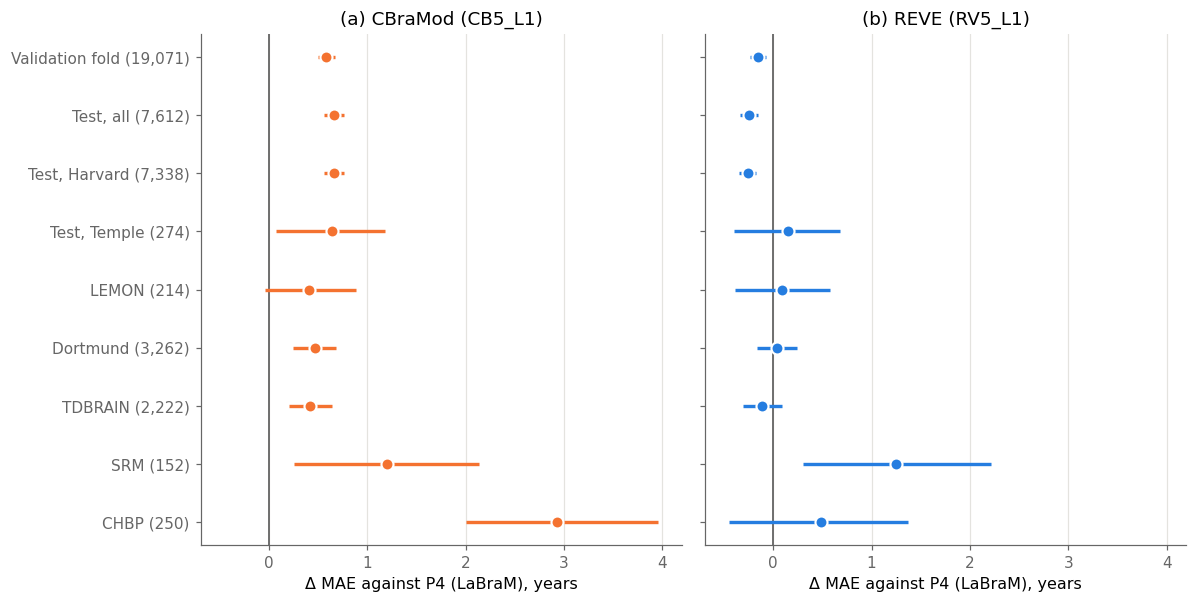

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.6), sharey=True)
y = np.arange(len(T31))[::-1]
lo = min(T31[f"Δ {m} lo"].min() for m in (fc.CB, fc.RV)) - 0.25
hi = max(T31[f"Δ {m} hi"].max() for m in (fc.CB, fc.RV)) + 0.25
for ax, m in zip(axes, (fc.CB, fc.RV)):
    ax.axvline(0, color=fc.MUTED, lw=1.2, zorder=1)
    ax.hlines(y, T31[f"Δ {m} lo"], T31[f"Δ {m} hi"], color=fc.COLOR[m], lw=2.2, zorder=2)
    ax.scatter(T31[f"Δ {m}"], y, s=62, color=fc.COLOR[m], edgecolor="white", linewidth=1.4, zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{name} ({int(n):,})" for name, n in zip(T31.index, T31["n"])])
    ax.set_xlim(lo, hi)
    ax.set_xlabel("Δ MAE against P4 (LaBraM), years")
    ax.set_title(f"{m} ({'CB5_L1' if m == fc.CB else 'RV5_L1'})")
    fc.style(ax, "x")
finish(fig, list(axes), "delta_per_cohort.png")

- **REVE passes the decision rule, CBraMod does not** (Table 3.1, Figure 3.1). REVE wins on the
  Harvard test recordings (−0.26 years) and does not lose on LEMON (+0.09) or Dortmund (+0.04),
  whose intervals include 0. CBraMod loses on the Harvard test recordings (+0.66) and on Dortmund
  (+0.46).
- **REVE's gain is in the training domain.** On the validation fold and the test split it is
  0.16 to 0.26 years better; on four external cohorts it is level, and on SRM, the smallest
  (152 recordings), it is 1.25 years worse. On the 274 Temple test recordings it is level.
- **CBraMod is worse than P4 (LaBraM) on every cohort** (on LEMON the interval just includes 0),
  most on CHBP (+2.9 years), the cohort recorded with another type of device.

### Figure 3.2. Brain-age gap per cohort

Distribution of the gap (Eq. (2.3)) per cohort for the three models: box = middle half of the
recordings (quartiles), black line = median, whiskers = 5th to 95th percentile, dot = mean;
recordings and mean real age in brackets. (a) The gap as predicted; (b) after the linear
age-bias correction of Section 4 (Eq. (4.1)), which removes the part of the gap that the real age
alone predicts, fitted on the validation fold (so the validation fold is centred on 0 by
construction). Single recordings are not drawn.

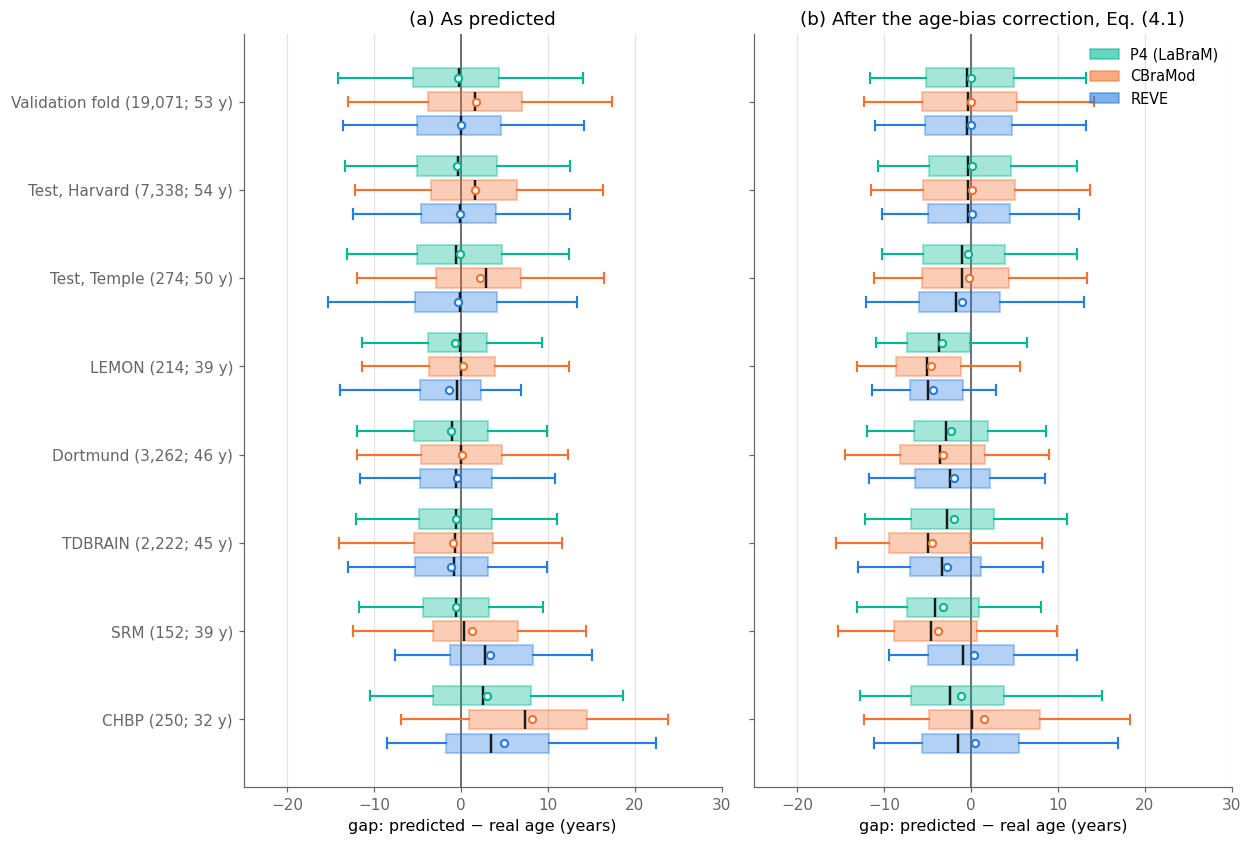

In [4]:
GAPSETS = [("Validation fold", val), ("Test, Harvard", test_all[test_all["family"] == "harvard"]),
           ("Test, Temple", test_all[test_all["family"] == "temple"])]
GAPSETS += [(fc.NAME[c], ext[ext["cohort"] == c]) for c in fc.EXTERNAL]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 7.8), sharey=True)
base = np.arange(len(GAPSETS))[::-1].astype(float)
for ax, corrected in zip(axes, (False, True)):
    ax.axvline(0, color=fc.MUTED, lw=1.2, zorder=1)
    handles = []
    for k, m in enumerate(fc.SINGLE):
        data = []
        for name, x in GAPSETS:
            pred = fc.bias_corrected(x, val, [m])[m] if corrected else x[m]
            data.append((pred - x["age"]).to_numpy())
        handles.append(fc.gap_boxes(ax, data, base + 0.27 - 0.27 * k, fc.COLOR[m], label=m))
    ax.set_yticks(base)
    ax.set_yticklabels([f"{n} ({len(x):,}; {x['age'].mean():.0f} y)" for n, x in GAPSETS])
    ax.set_xlabel("gap: predicted − real age (years)")
    ax.set_title("After the age-bias correction, Eq. (4.1)" if corrected else "As predicted")
    ax.set_xlim(-25, 30)
    fc.style(ax, "x")
axes[1].legend(handles=handles, loc="upper right")
finish(fig, list(axes), "gap_per_cohort.png")

- **As predicted, the median gap is close to 0 on the training-hospital sets** for P4 (LaBraM) and
  REVE (−0.5 to 0.0 years) and +1.6 to +2.9 for CBraMod (Figure 3.2(a), Table 3.2). On the
  external cohorts it lies between −1.0 and +0.4 years, except on CHBP (+2.5 to +7.4) and for REVE
  on SRM (+2.7).
- **The spread is similar for P4 (LaBraM) and REVE** (interquartile range 6.8 to 9.9 years outside
  CHBP) and wider for CBraMod (7.6 to 10.9); CHBP has the widest (11.3 to 13.5).
- **After the age-bias correction the external cohorts lie below 0** (Figure 3.2(b), Table 3.2):
  their participants look 1 to 5 years younger than the hospital patients of the same age on
  which the correction was fitted (medians −0.9 to −5.1). Only CBraMod on CHBP is not below 0
  (+0.1), because its uncorrected gap there is high (+7.4).

### Table 3.2. Median brain-age gap per cohort

Median gap (Eq. (2.3)) in years per cohort and model, as predicted and after the age-bias
correction (Eq. (4.1)); the numbers behind the black lines of Figure 3.2.

In [5]:
rows = []
for name, x in GAPSETS:
    row = {"": name, "n": f"{len(x):,}", "mean age": x["age"].mean()}
    for m in fc.SINGLE:
        row[f"{m}"] = (x[m] - x["age"]).median()
    for m in fc.SINGLE:
        row[f"{m}, corrected"] = (fc.bias_corrected(x, val, [m])[m] - x["age"]).median()
    rows.append(row)
T32 = pd.DataFrame(rows).set_index("")
table(T32, "3.2", digits=1)

,n,mean age,P4 (LaBraM),CBraMod,REVE,"P4 (LaBraM), corrected","CBraMod, corrected","REVE, corrected"
,,,,,,,,
Validation fold,"19,071",53.3,-0.3,1.6,0.0,-0.5,-0.4,-0.5
"Test, Harvard","7,338",54.1,-0.3,1.6,-0.1,-0.3,-0.3,-0.4
"Test, Temple",274,50.4,-0.5,2.9,-0.1,-1.0,-1.1,-1.7
LEMON,214,39.2,-0.2,-0.0,-0.5,-3.7,-5.1,-4.9
Dortmund,"3,262",46.1,-1.0,-0.0,-0.6,-2.9,-3.6,-2.4
TDBRAIN,"2,222",45.3,-0.6,-0.7,-0.8,-2.8,-5.0,-3.3
SRM,152,38.8,-0.6,0.4,2.7,-4.2,-4.6,-0.9
CHBP,250,31.7,2.5,7.4,3.5,-2.4,0.1,-1.5


How much do the three models agree on which recordings are hard? For models $A$ and $B$ with
gaps $g^A_r$ and $g^B_r$ (Eq. (2.3)) on the same $n$ recordings:

$$ r = \operatorname{corr}\big(g^A, g^B\big) \tag{3.1} $$

the Pearson correlation over recordings (the same for the absolute errors $\lvert g^A_r \rvert$
and $\lvert g^B_r \rvert$), the share of recordings on which $B$ has the smaller error,

$$ p_{B<A} = \frac{100}{n} \sum_r \mathbf{1}\big[\lvert g^B_r \rvert < \lvert g^A_r \rvert\big] \tag{3.2} $$

and the share on which the two errors differ by more than 5 years,

$$ p_{>5} = \frac{100}{n} \sum_r \mathbf{1}\big[\, \big\lvert \lvert g^A_r \rvert - \lvert g^B_r \rvert \big\rvert > 5 \,\big] \tag{3.3} $$

### Table 3.3. How much the errors of the three models agree

Per pair of models ($A$ against $B$) and set of recordings: correlation of the gaps and of the
absolute errors (Eq. (3.1)), the share of recordings with the smaller error for $B$ (Eq. (3.2),
%) and the share with errors more than 5 years apart (Eq. (3.3), %). Held-out = the validation
fold and the test split together (26,681 adult recordings).

In [6]:
PAIRS = [(fc.P4, fc.CB), (fc.P4, fc.RV), (fc.CB, fc.RV)]
rows = []
for name, x in (("Held-out", heldout), ("External cohorts", ext)):
    for a, b in PAIRS:
        ga, gb = x[a] - x["age"], x[b] - x["age"]
        rows.append({"Recordings": name, "A against B": f"{a} against {b}", "n": f"{len(x):,}",
                     "r of gaps": np.corrcoef(ga, gb)[0, 1],
                     "r of absolute errors": np.corrcoef(ga.abs(), gb.abs())[0, 1],
                     "B smaller error (%)": 100 * np.mean(gb.abs() < ga.abs()),
                     "errors > 5 y apart (%)": 100 * np.mean((ga.abs() - gb.abs()).abs() > 5)})
T33 = pd.DataFrame(rows).set_index("Recordings")
table(T33, "3.3")

,A against B,n,r of gaps,r of absolute errors,B smaller error (%),errors > 5 y apart (%)
Recordings,,,,,,
Held-out,P4 (LaBraM) against CBraMod,"26,681",0.84,0.70,44.80,23.82
Held-out,P4 (LaBraM) against REVE,"26,681",0.84,0.73,51.99,18.62
Held-out,CBraMod against REVE,"26,681",0.82,0.68,56.49,24.95
External cohorts,P4 (LaBraM) against CBraMod,"6,100",0.73,0.56,45.66,21.80
External cohorts,P4 (LaBraM) against REVE,"6,100",0.74,0.59,50.33,19.15
External cohorts,CBraMod against REVE,"6,100",0.72,0.54,54.43,23.95


### Figure 3.3. Errors of the three models against each other

(a) P4 (LaBraM) against CBraMod, (b) P4 (LaBraM) against REVE, (c) CBraMod against REVE: the
absolute error of one model against that of the other for each held-out recording, as a hexagon
density (log scale; hexagons with fewer than 10 recordings are not drawn); below the dashed
diagonal the second model is better; r = Eq. (3.1) of the absolute errors. (d) MAE per group:
each point is one group of recordings, MAE of P4 (LaBraM) across against MAE of REVE (blue) or
CBraMod (orange) up; the marker shows the kind of group (the cohorts of Table 3.1, the age bands
of Tables 4.1 and 4.2, the Harvard pathology groups of Table 7.1). The age bands, pathology groups
and Table 3.3 are explained in Sections 4 and 7. Below the diagonal the model
is better than P4 (LaBraM) for that group.

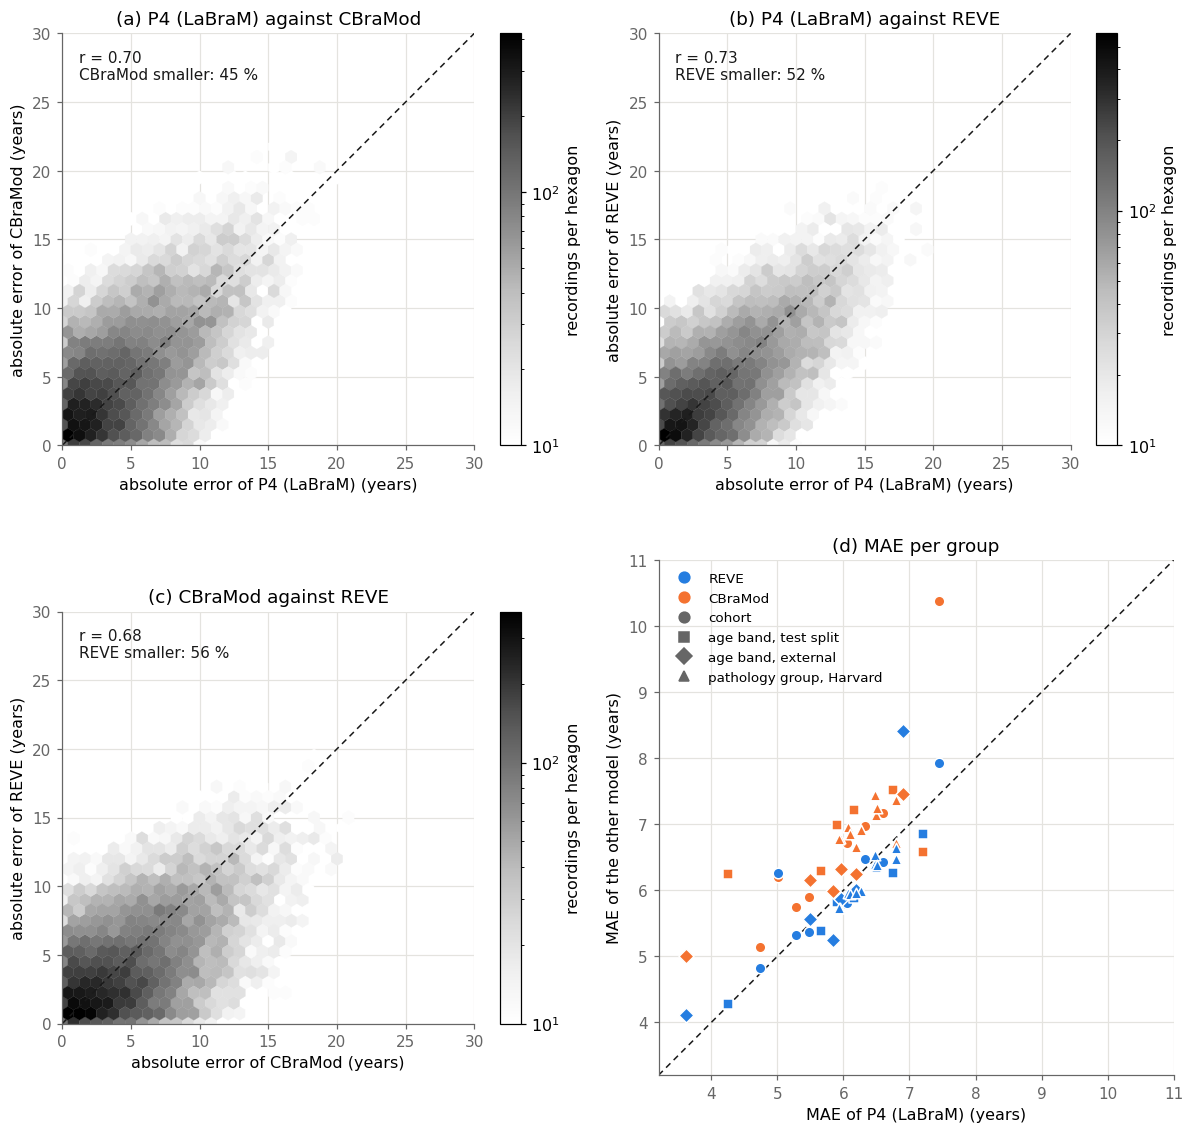

In [7]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(2, 2, figsize=(11, 10.8))
axes = list(axes.flat)
for ax, (a, b), tag in zip(axes[:3], PAIRS, "abc"):
    ea, eb = (heldout[a] - heldout["age"]).abs(), (heldout[b] - heldout["age"]).abs()
    hb = ax.hexbin(ea, eb, gridsize=36, extent=(0, 30, 0, 30), mincnt=fc.MIN_SUBJECTS, bins="log", cmap="Greys",
                   linewidths=0.2, zorder=1)
    ax.plot([0, 30], [0, 30], color=fc.INK, lw=1, ls=(0, (4, 3)), zorder=2)
    ax.set_xlim(0, 30)
    ax.set_ylim(0, 30)
    ax.set_aspect("equal")
    ax.set_xlabel(f"absolute error of {a} (years)")
    ax.set_ylabel(f"absolute error of {b} (years)")
    ax.set_title(f"({tag}) {a} against {b}")
    ax.text(0.04, 0.96, f"r = {np.corrcoef(ea, eb)[0, 1]:.2f}\n{b} smaller: {100 * np.mean(eb < ea):.0f} %",
            transform=ax.transAxes, va="top", fontsize=10, color=fc.INK)
    fig.colorbar(hb, ax=ax, shrink=0.78, label="recordings per hexagon")
    fc.style(ax)
ax = axes[3]
kinds = {"cohort": ("o", fc.compare(GAPSETS + [("Test, all", test_all)], fc.SINGLE)),
         "age band, test split": ("s", fc.compare(fc.band_sets(test)[1:], fc.SINGLE)),
         "age band, external": ("D", fc.compare(fc.band_sets(ext)[1:], fc.SINGLE))}
pg = path[(path["source"] == "pooled") & (path["family"] == "harvard") & (path["kind"] == "pathology")
          & (~path["suppressed"].astype(bool)) & (path["n_subjects"] >= 30)]
kinds["pathology group, Harvard"] = ("^", pd.DataFrame({fc.P4: pg["mae_P4"].to_numpy(), fc.RV: pg["mae_REVE"].to_numpy(),
                                                       fc.CB: pg["mae_CBraMod"].to_numpy()}))
for kind, (marker, df) in kinds.items():
    for m in (fc.CB, fc.RV):
        ax.scatter(df[fc.P4], df[m], marker=marker, s=48, color=fc.COLOR[m], edgecolor="white", lw=1, zorder=3)
lo_, hi_ = 3.2, 11
ax.plot([lo_, hi_], [lo_, hi_], color=fc.INK, lw=1, ls=(0, (4, 3)), zorder=2)
ax.set_xlim(lo_, hi_)
ax.set_ylim(lo_, hi_)
ax.set_aspect("equal")
ax.set_xlabel(f"MAE of {fc.P4} (years)")
ax.set_ylabel("MAE of the other model (years)")
ax.set_title("(d) MAE per group")
handles = [Line2D([], [], color=fc.COLOR[m], marker="o", ls="", ms=7, label=m) for m in (fc.RV, fc.CB)]
handles += [Line2D([], [], color=fc.MUTED, marker=mk, ls="", ms=7, label=k) for k, (mk, _) in kinds.items()]
ax.legend(handles=handles, loc="upper left", fontsize=8.8)
fc.style(ax)
finish(fig, None, "error_pairs.png")      # letters set above (colourbars shift the panels)

- **The three models make largely the same errors** (Table 3.3, Figure 3.3(a–c)): their gaps
  correlate at 0.82 to 0.84 on the held-out recordings and 0.72 to 0.74 on the external cohorts,
  their absolute errors at 0.68 to 0.73 and 0.54 to 0.59. A recording that is hard for one model is usually hard
  for the others.
- **REVE's gain is a small shift spread over many recordings**: it has the smaller error than P4
  (LaBraM) on 52 % of the held-out recordings and 50 % outside. On about one recording in five the
  two errors are more than 5 years apart, which is why their mean is better than either alone
  (Section 8).
- **Per group** (Figure 3.3(d)), REVE lies below or on the diagonal for every group of the
  training hospitals except the Temple test recordings (+0.15 years). Outside them its points lie
  on or above the diagonal, clearly above for SRM, CHBP and the external age bands 18–29 and 70+.
  CBraMod lies above the diagonal for every group except the test band 70+ and dementia.

## 4. Accuracy per age band

The same comparison within age bands (18–29, …, 70+ years, as in the technical report), for the
adult test recordings (7,610: the test split without its 2 minors) and the adults of the external
cohorts. The external bands mix the cohorts differently: LEMON has only young and old adults,
CHBP mostly and SRM in more than half people under 40, Dortmund and TDBRAIN all ages; 70+ is
Dortmund and TDBRAIN with 24 LEMON recordings.

### Table 4.1. MAE per age band, test split

MAE in years (Eq. (2.1)) of each single model and Δ against P4 (LaBraM) (Eq. (2.2)) with its
95 % interval; n = recordings, People = the people they come from.

In [8]:
T41 = fc.compare(fc.band_sets(test), fc.SINGLE, deltas=(fc.CB, fc.RV))
table(fc.shown(T41, (fc.CB, fc.RV)), "4.1")

,n,People,P4 (LaBraM),CBraMod,REVE,Δ CBraMod,Δ REVE
,,,,,,,
all ages,"7,610","6,133",6.05,6.71,5.81,"+0.66 [+0.56, +0.77]","−0.24 [−0.33, −0.16]"
18–29,"1,246","1,050",4.25,6.24,4.28,"+2.00 [+1.76, +2.24]","+0.03 [−0.15, +0.22]"
30–39,846,725,6.16,7.21,5.89,"+1.05 [+0.74, +1.35]","−0.27 [−0.55, −0.02]"
40–49,899,738,6.74,7.51,6.26,"+0.77 [+0.45, +1.10]","−0.48 [−0.74, −0.23]"
50–59,"1,212","1,025",5.91,7.00,5.82,"+1.09 [+0.83, +1.34]","−0.08 [−0.32, +0.15]"
60–69,"1,456","1,185",5.66,6.29,5.38,"+0.62 [+0.39, +0.86]","−0.29 [−0.50, −0.07]"
70+,"1,951","1,591",7.21,6.58,6.85,"−0.63 [−0.82, −0.44]","−0.36 [−0.55, −0.18]"


### Table 4.2. MAE per age band, external cohorts

As Table 4.1, for the adults of LEMON, Dortmund, TDBRAIN, SRM and CHBP together.

In [9]:
T42 = fc.compare(fc.band_sets(ext), fc.SINGLE, deltas=(fc.CB, fc.RV))
table(fc.shown(T42, (fc.CB, fc.RV)), "4.2")

,n,People,P4 (LaBraM),CBraMod,REVE,Δ CBraMod,Δ REVE
,,,,,,,
all ages,"6,100","2,244",5.42,5.98,5.45,"+0.56 [+0.41, +0.71]","+0.03 [−0.11, +0.18]"
18–29,"1,323",643,3.61,5.01,4.12,"+1.40 [+1.10, +1.71]","+0.50 [+0.26, +0.77]"
30–39,"1,180",480,5.49,6.15,5.57,"+0.66 [+0.35, +0.97]","+0.08 [−0.22, +0.40]"
40–49,"1,096",400,5.96,6.33,5.86,"+0.37 [+0.04, +0.68]","−0.10 [−0.40, +0.20]"
50–59,"1,287",426,5.84,5.99,5.25,"+0.15 [−0.18, +0.48]","−0.59 [−0.89, −0.28]"
60–69,895,300,6.19,6.24,6.01,"+0.05 [−0.31, +0.43]","−0.19 [−0.56, +0.19]"
70+,319,118,6.90,7.46,8.41,"+0.56 [−0.06, +1.24]","+1.51 [+0.93, +2.10]"


### Table 4.3. MAE per age band of the ensembles

MAE in years of P4ens (LaBraM) and of that ensemble with REVE as a sixth member; Δ = the second
minus the first (Eq. (2.2) with P4ens (LaBraM) in place of P4 (LaBraM)), 95 % interval. Adult
test recordings (7,610; Table 8.1 has all 7,612). The validation fold cannot be used: the other
four P4 models trained on it. One member, the fold-3 model, is scored on the test split at its
epoch 15 instead of its best epoch 16, whose test predictions were not saved; its test MAE is
6.12 years at both.

In [10]:
rows = []
for name, x in (("Test", test), ("External", ext)):
    t = fc.compare(fc.band_sets(x), [fc.P4ENS, fc.P4ENS_RV], deltas=(fc.P4ENS_RV,), ref=fc.P4ENS)
    t.index = [f"{name}, {i}" for i in t.index]
    rows.append(t)
T43 = pd.concat(rows)
T43.index.name = ""
table(fc.shown(T43, (fc.P4ENS_RV,)), "4.3")

,n,People,P4ens (LaBraM),P4ens (LaBraM) + REVE,Δ P4ens (LaBraM) + REVE
,,,,,
"Test, all ages","7,610","6,133",5.94,5.82,"−0.12 [−0.13, −0.10]"
"Test, 18–29","1,246","1,050",4.32,4.28,"−0.05 [−0.08, −0.02]"
"Test, 30–39",846,725,5.96,5.85,"−0.11 [−0.16, −0.07]"
"Test, 40–49",899,738,6.56,6.39,"−0.17 [−0.22, −0.12]"
"Test, 50–59","1,212","1,025",5.91,5.78,"−0.13 [−0.17, −0.09]"
"Test, 60–69","1,456","1,185",5.66,5.47,"−0.19 [−0.23, −0.16]"
"Test, 70+","1,951","1,591",6.90,6.82,"−0.08 [−0.11, −0.05]"
"External, all ages","6,100","2,244",5.32,5.15,"−0.17 [−0.19, −0.14]"
"External, 18–29","1,323",643,3.64,3.62,"−0.02 [−0.06, +0.02]"


### Figure 4.1. Error and mean gap per age band

(a) MAE (Eq. (2.1)) per age band on the adult test recordings, (b) mean gap (Eq. (2.3)) per age
band with its 95 % interval (Eq. (2.4)) on the same recordings, (c) and (d) the same for the
external cohorts; the three models and the two ensembles. Above 0 in (b) and (d) the models see
people as older than they are.

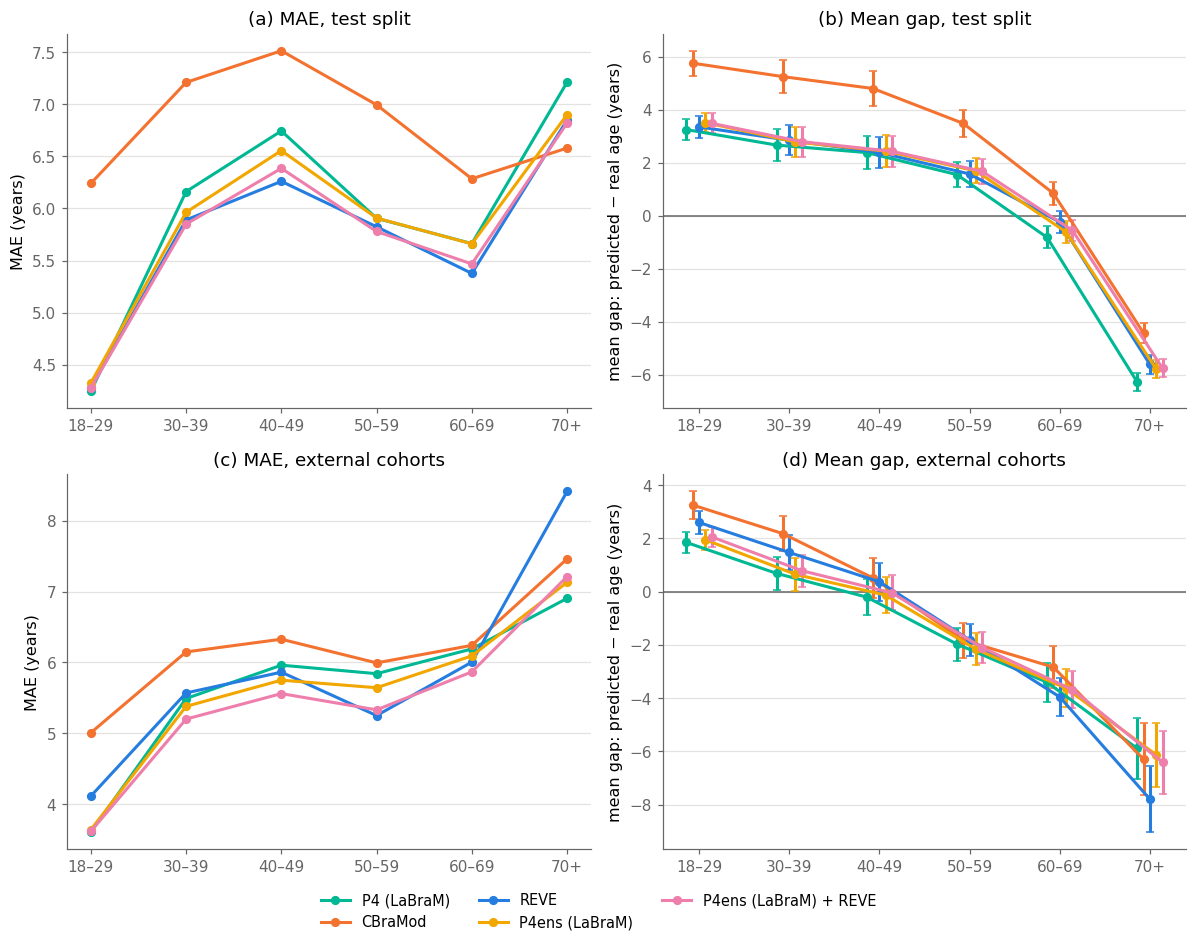

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8.6))
for row, (name, x) in enumerate((("test split", test), ("external cohorts", ext))):
    t = fc.compare(fc.band_sets(x)[1:], fc.ALL)
    g = fc.band_gap(x, fc.ALL)
    xs = np.arange(len(t))
    ax = axes[row, 0]
    for m in fc.ALL:
        ax.plot(xs, t[m], marker="o", ms=5, lw=2, color=fc.COLOR[m], label=m)
    ax.set_xticks(xs)
    ax.set_xticklabels(t.index)
    ax.set_ylabel("MAE (years)")
    ax.set_title(f"MAE, {name}")
    fc.style(ax, "y")
    ax = axes[row, 1]
    ax.axhline(0, color=fc.MUTED, lw=1)
    for k, m in enumerate(fc.ALL):
        gm = g[g["model"] == m]
        off = (k - 2) * 0.07
        ax.errorbar(np.arange(len(gm)) + off, gm["gap"], yerr=1.96 * gm["se"], marker="o", ms=5, lw=2,
                    capsize=2.5, color=fc.COLOR[m], label=m)
    ax.set_xticks(np.arange(len(t)))
    ax.set_xticklabels(t.index)
    ax.set_ylabel("mean gap: predicted − real age (years)")
    ax.set_title(f"Mean gap, {name}")
    fc.style(ax, "y")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.tight_layout(rect=(0, 0.05, 1, 1))
panel_labels(list(axes.flat))
fig.legend(handles, labels, loc="lower center", ncol=3)
assert_max_columns(fig)
fig.savefig(os.path.join(FIGS, "age_bands.png"), dpi=150, bbox_inches="tight")
plt.show()

Brain-age studies usually remove the age-dependent part of the gap before they interpret it, by a
linear fit of the gap on the real age (Beheshti et al. 2019; de Lange and Cole 2020; the "gap
linear" correction of Gemein et al. 2024, *Imaging Neuroscience* 2, doi:10.1162/imag_a_00210; see
also `docs/tech_report/brain_age_tech_report.md`). With $a, b$ fitted by least squares for each
model on the hospital recordings of the validation fold ($g_r = a + b\,y_r$,
`labram/eval/cv_compare.py::bias_correct`), the corrected prediction of a recording is

$$ \hat y_r^{\mathrm{corr}} = \hat y_r - (a + b\, y_r) \tag{4.1} $$

### Table 4.4. MAE after the linear age-bias correction

MAE in years (Eq. (2.1)) of the corrected predictions (Eq. (4.1)) and Δ against the corrected P4
(LaBraM) (Eq. (2.2)) with its 95 % interval. Fitted $a$ and $b$: P4 (LaBraM) 10.8 years and −0.21,
CBraMod 13.8 and −0.23, REVE 11.1 and −0.21. The correction uses the real age of each recording,
so the corrected error is not a prediction error: it measures how well a model ranks people of
the same age, which is what a brain-age gap is used for.

In [12]:
sets = []
for name, x in (("Test, all", test_all), ("Test, Harvard", test_all[test_all["family"] == "harvard"]),
                ("Test, Temple", test_all[test_all["family"] == "temple"]), ("External cohorts", ext)):
    sets.append((name, fc.bias_corrected(x, val, fc.SINGLE)))
sets += [(fc.NAME[c], fc.bias_corrected(ext[ext["cohort"] == c], val, fc.SINGLE)) for c in fc.EXTERNAL]
T44 = fc.compare(sets, fc.SINGLE, deltas=(fc.CB, fc.RV))
table(fc.shown(T44, (fc.CB, fc.RV)), "4.4")

,n,People,P4 (LaBraM),CBraMod,REVE,Δ CBraMod,Δ REVE
,,,,,,,
"Test, all","7,612","6,135",5.72,6.28,5.65,"+0.56 [+0.46, +0.65]","−0.07 [−0.15, +0.02]"
"Test, Harvard","7,338","5,884",5.71,6.28,5.64,"+0.57 [+0.47, +0.66]","−0.07 [−0.16, +0.01]"
"Test, Temple",274,251,5.84,6.17,6.03,"+0.33 [−0.17, +0.82]","+0.19 [−0.39, +0.72]"
External cohorts,"6,100","2,244",5.80,6.75,5.62,"+0.95 [+0.80, +1.10]","−0.18 [−0.31, −0.05]"
LEMON,214,214,5.33,6.35,5.37,"+1.02 [+0.57, +1.47]","+0.04 [−0.44, +0.53]"
Dortmund,"3,262",608,5.53,6.49,5.44,"+0.96 [+0.75, +1.17]","−0.10 [−0.29, +0.09]"
TDBRAIN,"2,222","1,062",6.09,7.04,5.75,"+0.95 [+0.73, +1.19]","−0.34 [−0.52, −0.15]"
SRM,152,110,5.90,7.10,5.91,"+1.20 [+0.32, +2.12]","+0.01 [−0.86, +0.92]"
CHBP,250,250,7.02,7.74,6.88,"+0.72 [−0.09, +1.55]","−0.14 [−0.93, +0.58]"


- **On the test split REVE is better than P4 (LaBraM) in four of six age bands** (30–49 and 60+,
  Table 4.1) and level in the other two; CBraMod is worse in every band except 70+.
- **Outside the training data REVE's result depends on age** (Table 4.2): it is 0.6 years better
  at 50–59, level at 30–49 and 60–69, and worse at the extremes: +0.5 years at 18–29 and +1.5 at
  70+. More than half of SRM's participants are under 40, so the young band contributes to REVE's
  loss there.
- **Every model compresses the age range** (Figure 4.1(b, d)): it predicts young adults 2 to 6
  years too old and people over 70 4 to 8 years too young. CBraMod predicts about 2 years older
  than P4 (LaBraM) in every band below 60 on the test split. That makes it worse for the young
  and better for the old, the only band where it beats P4 (LaBraM) (Table 4.1).
- **REVE as a sixth ensemble member helps in almost every band** (Table 4.3): by 0.05 to 0.19
  years in every band of the test split, and by 0.18 to 0.31 years at 30–69 on the external
  cohorts; at 18–29 and 70+ outside the training data it changes nothing.
- **After the linear age-bias correction** (Table 4.4) REVE's lead on the test split shrinks to
  level with P4 (LaBraM) (−0.07 years, interval −0.15 to +0.02). On the external cohorts together
  REVE becomes better (−0.18, interval −0.31 to −0.05), mainly on TDBRAIN (−0.34); each other
  external cohort alone is level. The correction, fitted on hospital patients, raises P4 (LaBraM)'s
  error on the external cohorts, whose age bias differs. CBraMod stays behind.

## 5. Predicted against real age

How the predictions spread around the real age, overall (Figure 5.1), by EEG-report status
(Figure 5.2), by pathology group (Figure 5.3), and as single recordings for the open cohorts
(Figure 5.4). The recordings are the validation fold and the test split together (Harvard and
Temple, 26,681 adult recordings). Their data use agreements do not allow single recordings to be
shown, so Figure 5.1 shows how many recordings fall in each small area of the plot, and
Figures 5.2 and 5.3 show the mean gap of each group in 5-year age bins; areas and bins with
fewer than 10 recordings (Figure 5.1) or 30 recordings or 10 people (Figures 5.2, 5.3) are left
out.

### Figure 5.1. Predicted against real age, all held-out recordings

(a) P4 (LaBraM), (b) CBraMod, (c) REVE: each hexagon is shaded by the number of recordings with
that real and predicted age (log scale); the dashed diagonal is a perfect prediction, the
coloured line the mean prediction per 5-year bin of real age. (d) The three mean-prediction
lines together. A line flatter than the diagonal means the model compresses the age range.

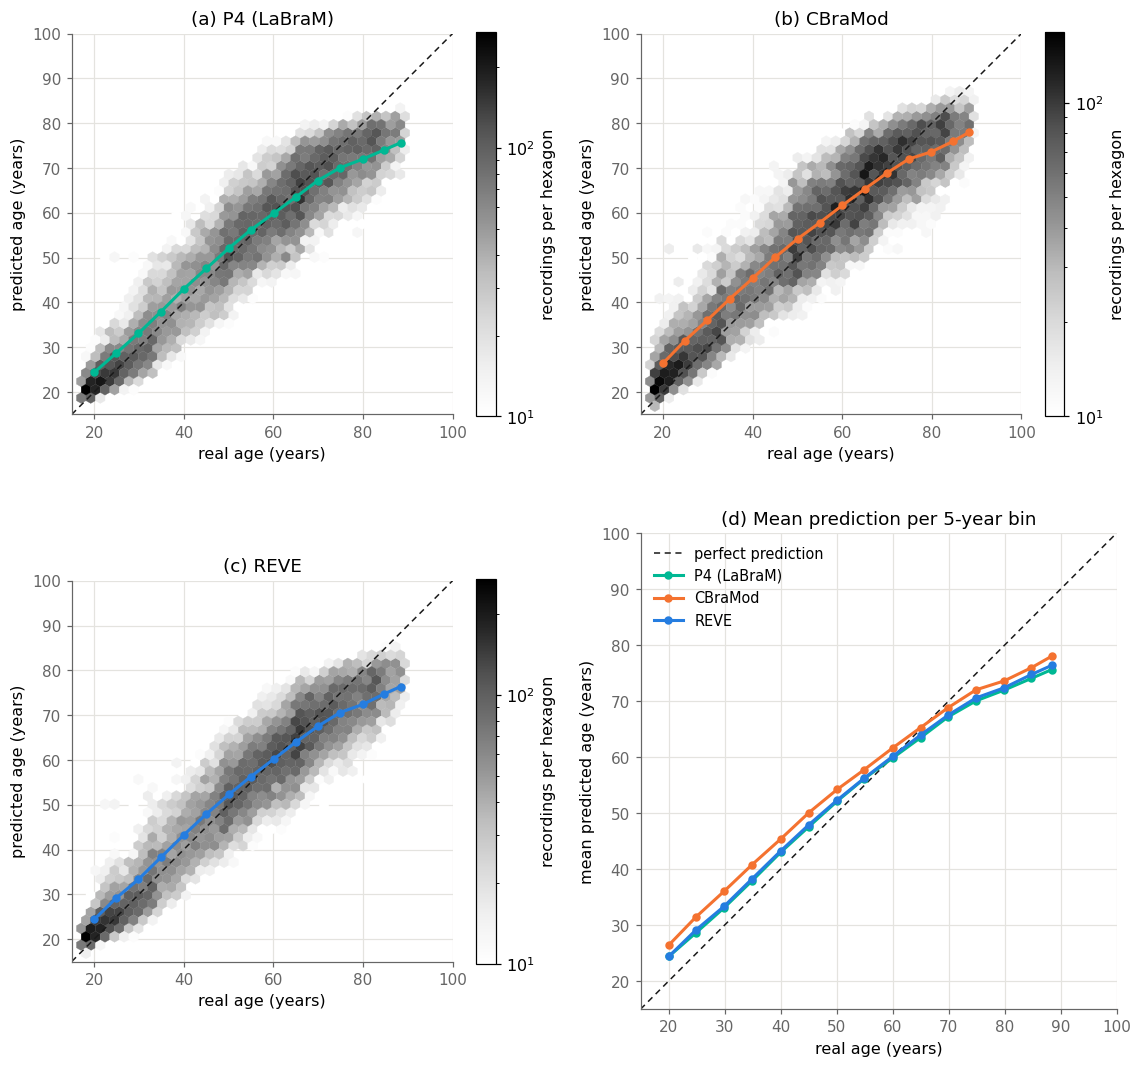

In [13]:
fig = plt.figure(figsize=(10.5, 10.2))
gs = fig.add_gridspec(2, 2)
axes = [fig.add_subplot(gs[i, j]) for i in range(2) for j in range(2)]
for ax, m, tag in zip(axes[:3], fc.SINGLE, "abc"):
    hb = fc.density(ax, heldout, m)
    ax.set_title(f"({tag}) {m}")
    ax.set_xlabel("real age (years)")
    ax.set_ylabel("predicted age (years)")
    fig.colorbar(hb, ax=ax, shrink=0.78, label="recordings per hexagon")
    fc.style(ax)
ax = axes[3]
ax.plot([15, 100], [15, 100], color=fc.INK, lw=1, ls=(0, (4, 3)), label="perfect prediction")
for m in fc.SINGLE:
    fc.curve(ax, fc.binned(heldout, m), fc.COLOR[m], m, y="pred", band=False)
ax.set_xlim(15, 100)
ax.set_ylim(15, 100)
ax.set_aspect("equal")
ax.set_xlabel("real age (years)")
ax.set_ylabel("mean predicted age (years)")
ax.set_title("(d) Mean prediction per 5-year bin")
ax.legend(loc="upper left")
fc.style(ax)
finish(fig, None, "density.png")      # letters set above

### Figure 5.2. Mean gap by EEG-report status

The gap (Eq. (2.3)) is the vertical distance of a recording from the diagonal of Figure 5.1.
(a) P4 (LaBraM), (b) CBraMod, (c) REVE: mean gap per 5-year bin of real age for recordings with a
normal EEG report, an abnormal report and no report, with 95 % bands (Eq. (2.4)). (d) Abnormal
minus normal report per bin for the three models: how much older an abnormal EEG makes a person
look at the same age.

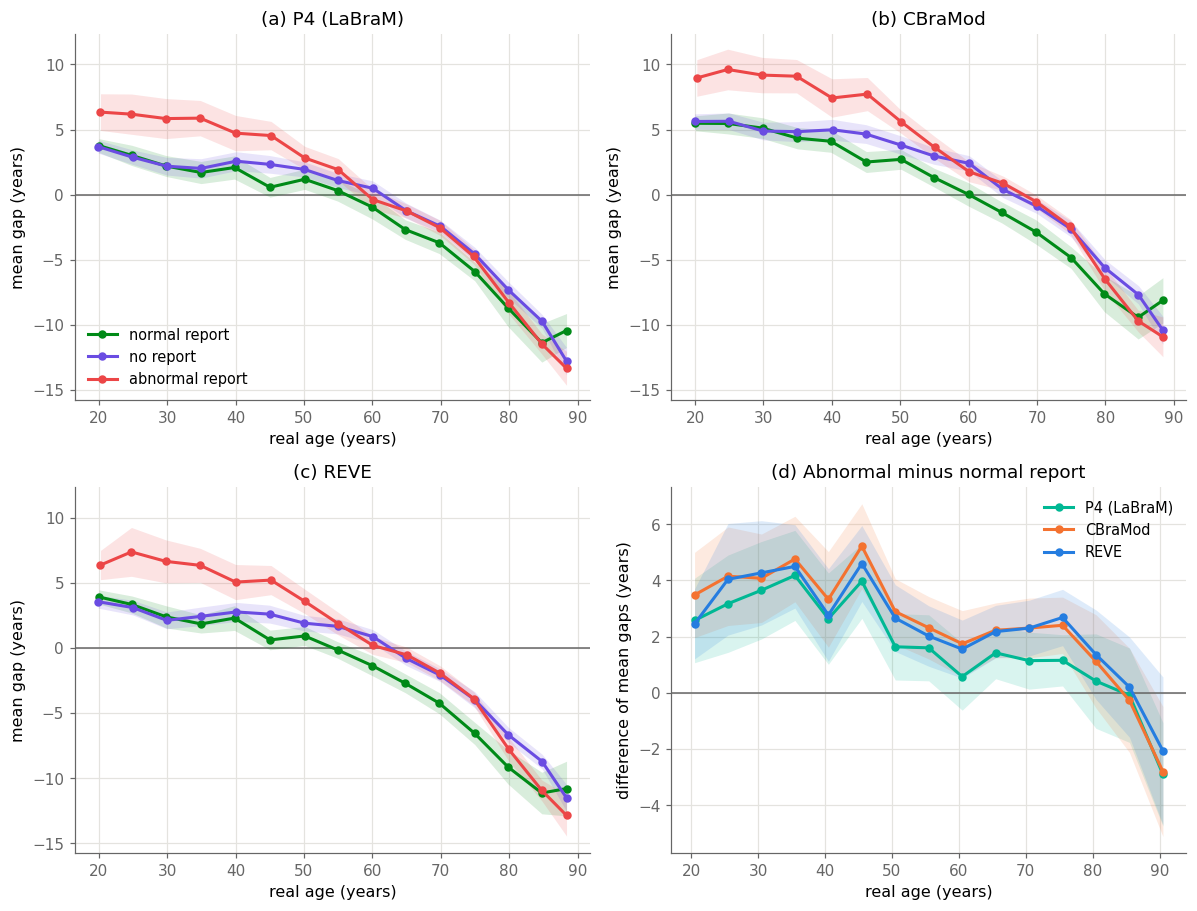

In [14]:
NAMES = {"normal": "normal report", "abnormal": "abnormal report", "unlabelled": "no report"}
fig, axes = plt.subplots(2, 2, figsize=(11, 8.4))
axes = list(axes.flat)
for ax, m in zip(axes[:3], fc.SINGLE):
    ax.axhline(0, color=fc.MUTED, lw=1)
    for lab in ("normal", "unlabelled", "abnormal"):
        fc.curve(ax, fc.binned(heldout[heldout["label"] == lab], m), fc.STATUS_COLOR[lab], NAMES[lab])
    ax.set_title(m)
    ax.set_xlabel("real age (years)")
    ax.set_ylabel("mean gap (years)")
    fc.style(ax)
lims = (min(a.get_ylim()[0] for a in axes[:3]), max(a.get_ylim()[1] for a in axes[:3]))
for a in axes[:3]:
    a.set_ylim(lims)
axes[0].legend(loc="lower left")
ax = axes[3]
ax.axhline(0, color=fc.MUTED, lw=1)
for m in fc.SINGLE:
    a = fc.binned(heldout[heldout["label"] == "abnormal"], m).set_index("bin")
    n = fc.binned(heldout[heldout["label"] == "normal"], m).set_index("bin")
    j = a.join(n, lsuffix="_a", rsuffix="_n", how="inner")
    d, se = j["gap_a"] - j["gap_n"], np.sqrt(j["se_a"] ** 2 + j["se_n"] ** 2)
    ax.plot(j.index + 2.5, d, marker="o", ms=4.5, lw=2, color=fc.COLOR[m], label=m)
    ax.fill_between(j.index + 2.5, d - 1.96 * se, d + 1.96 * se, color=fc.COLOR[m], alpha=0.15, lw=0)
ax.set_title("Abnormal minus normal report")
ax.set_xlabel("real age (years)")
ax.set_ylabel("difference of mean gaps (years)")
ax.legend(loc="upper right")
fc.style(ax)
finish(fig, axes, "report_status.png")

### Figure 5.3. Mean gap by pathology group, Harvard

As Figure 5.2 for the Harvard recordings of three pathology groups and the healthy reference
group (a normal EEG report and a health record without any of the pathology groups; Section 7).
(a) P4 (LaBraM), (b) CBraMod, (c) REVE; (d) the healthy reference group for the three models.
Dementia has too few recordings below 50 to be shown there.

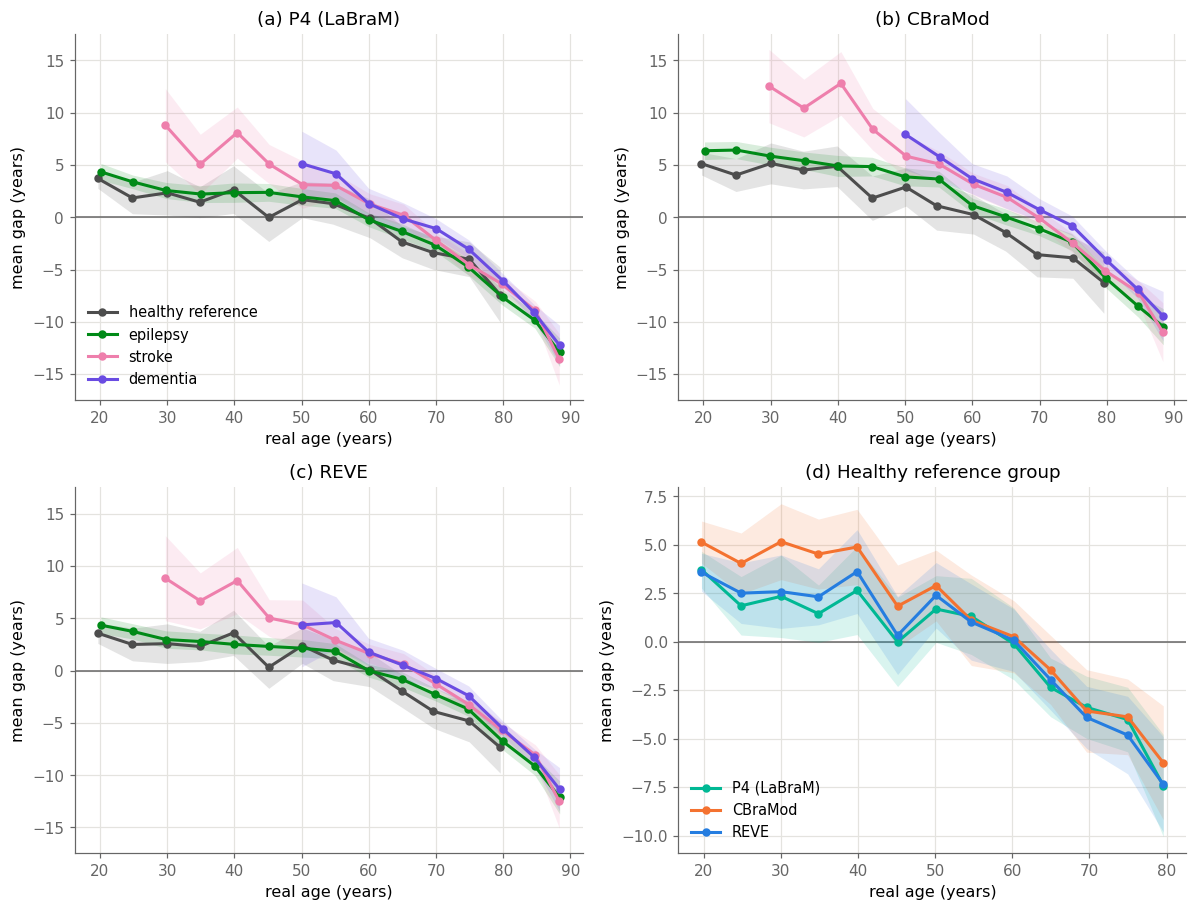

In [15]:
H = heldout[heldout["family"] == "harvard"]
GROUP_NAMES = {"reference": "healthy reference", "epilepsy": "epilepsy", "stroke": "stroke", "dementia": "dementia"}
fig, axes = plt.subplots(2, 2, figsize=(11, 8.4))
axes = list(axes.flat)
for ax, m in zip(axes[:3], fc.SINGLE):
    ax.axhline(0, color=fc.MUTED, lw=1)
    for g, name in GROUP_NAMES.items():
        mask = H["reference"] if g == "reference" else H[g] == 1
        fc.curve(ax, fc.binned(H[mask], m), fc.GROUP_COLOR[g], name)
    ax.set_title(m)
    ax.set_xlabel("real age (years)")
    ax.set_ylabel("mean gap (years)")
    fc.style(ax)
lims = (min(a.get_ylim()[0] for a in axes[:3]), max(a.get_ylim()[1] for a in axes[:3]))
for a in axes[:3]:
    a.set_ylim(lims)
axes[0].legend(loc="lower left")
ax = axes[3]
ax.axhline(0, color=fc.MUTED, lw=1)
for m in fc.SINGLE:
    fc.curve(ax, fc.binned(H[H["reference"]], m), fc.COLOR[m], m)
ax.set_title("Healthy reference group")
ax.set_xlabel("real age (years)")
ax.set_ylabel("mean gap (years)")
ax.legend(loc="lower left")
fc.style(ax)
finish(fig, axes, "pathology_curves.png")

### Figure 5.4. Predicted against real age, single recordings of the open cohorts

One point per recording and model: (a) LEMON (214 recordings; LEMON gives ages as 5-year ranges,
plotted at their midpoints, hence the columns), (b) Dortmund (3,262: up to four recordings per
session, some people with a second session 5 years later), (c) CHBP (250), all adults; the
dashed diagonal is a perfect prediction. (d) The mean prediction per 5-year bin of
real age, the three cohorts together.

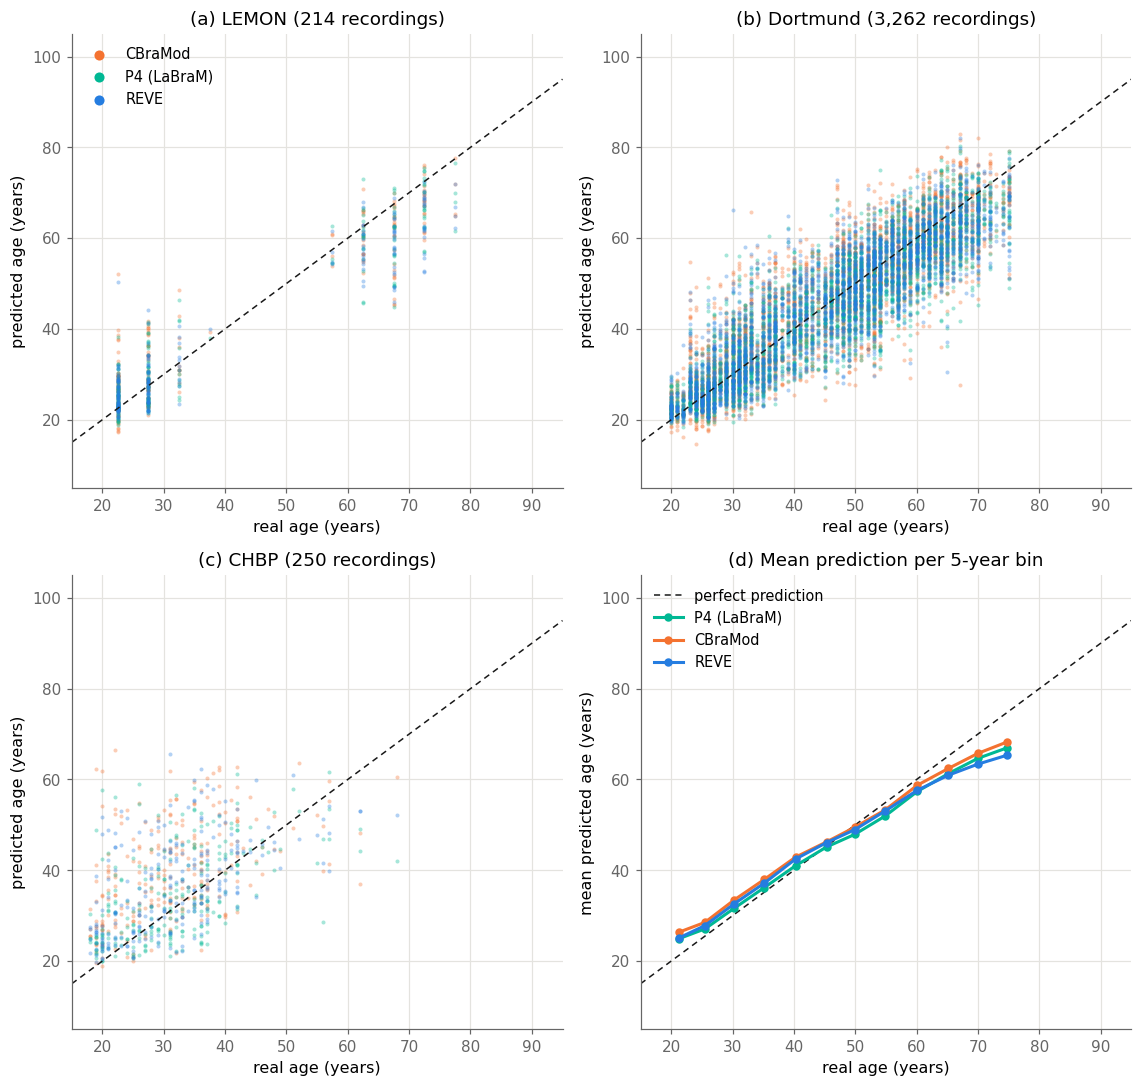

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 10.0))
axes = list(axes.flat)
O = ext[ext["cohort"].isin(fc.OPEN)]
for ax, c in zip(axes[:3], fc.OPEN):
    x = O[O["cohort"] == c]
    for m in (fc.CB, fc.P4, fc.RV):
        ax.scatter(x["age"], x[m], s=7, alpha=0.35, color=fc.COLOR[m], lw=0, label=m)
    ax.plot([15, 95], [15, 95], color=fc.INK, lw=1, ls=(0, (4, 3)))
    ax.set_xlim(15, 95)
    ax.set_ylim(5, 105)
    ax.set_title(f"{fc.NAME[c]} ({len(x):,} recordings)")
    ax.set_xlabel("real age (years)")
    ax.set_ylabel("predicted age (years)")
    fc.style(ax)
leg = axes[0].legend(loc="upper left", markerscale=2.5)
for h in leg.legend_handles:
    h.set_alpha(1)
ax = axes[3]
ax.plot([15, 95], [15, 95], color=fc.INK, lw=1, ls=(0, (4, 3)), label="perfect prediction")
for m in fc.SINGLE:
    fc.curve(ax, fc.binned(O, m), fc.COLOR[m], m, y="pred", band=False)
ax.set_xlim(15, 95)
ax.set_ylim(5, 105)
ax.set_title("Mean prediction per 5-year bin")
ax.set_xlabel("real age (years)")
ax.set_ylabel("mean predicted age (years)")
ax.legend(loc="upper left")
fc.style(ax)
finish(fig, axes, "open_cohorts_scatter.png")

- **The three models compress the age range in the same way** (Figure 5.1): the mean-prediction
  lines are flatter than the diagonal and cross it at about 60 years (P4 (LaBraM), REVE) or 65
  (CBraMod), so young adults are predicted too old and old people too young. P4 (LaBraM) and REVE lie almost on top of each
  other; CBraMod's line lies about 2 years higher below 60 (Figure 5.1(d)).
- **An abnormal EEG report makes a person look older up to about 80** (Figure 5.2), in all three
  models: by 2.5 to 5 years under 50 and by 0.5 to 2.7 years between 50 and 80; the difference
  vanishes above 85 and reverses at 90, where the bands are wide. Recordings without a report lie between the two. REVE and CBraMod separate
  abnormal from normal reports by about 1 year more than P4 (LaBraM) between 50 and 80
  (Figure 5.2(d)).
- **Stroke and dementia look older than the healthy reference at the same age, epilepsy a
  little older** (Figure 5.3), in all three models. In the healthy reference group REVE and P4
  (LaBraM) have nearly the same age bias; CBraMod's is about 1.5 to 3 years higher under 50
  (Figure 5.3(d)).
- **On the open cohorts** (Figure 5.4) the points of the three models overlap on LEMON and
  Dortmund. On CHBP most points lie above the diagonal: all three models see its participants as
  older, by a median of 2.5 years (P4 (LaBraM)), 3.5 (REVE) and 7.4 (CBraMod) (Table 3.2).

## 6. By EEG-report status

### Table 6.1. MAE by report status

The validation fold and the test split by the verdict of the clinical EEG report (normal,
abnormal, or no report in the source data), the Temple test recordings by report, and the TDBRAIN
adults split into healthy participants and all others. Columns as Table 3.1.

In [17]:
NAMES = {"normal": "normal report", "abnormal": "abnormal report", "unlabelled": "no report"}
sets = [(f"Validation, {NAMES[l]}", val[val["label"] == l]) for l in ("normal", "abnormal", "unlabelled")]
sets += [(f"Test, {NAMES[l]}", test_all[test_all["label"] == l]) for l in ("normal", "abnormal", "unlabelled")]
tt = test_all[test_all["family"] == "temple"]
sets += [(f"Test, Temple, {NAMES[l]}", tt[tt["label"] == l]) for l in ("normal", "abnormal")]
td = ext[ext["cohort"] == "tdbrain"]
sets += [("TDBRAIN, healthy", td[td["label"] == "normal"]), ("TDBRAIN, all others", td[td["label"] != "normal"])]
T61 = fc.compare(sets, fc.SINGLE, deltas=(fc.CB, fc.RV))
table(fc.shown(T61, (fc.CB, fc.RV)), "6.1")

,n,People,P4 (LaBraM),CBraMod,REVE,Δ CBraMod,Δ REVE
,,,,,,,
"Validation, normal report","4,927","3,744",6.01,6.54,5.86,"+0.53 [+0.37, +0.67]","−0.15 [−0.29, −0.01]"
"Validation, abnormal report","7,320","4,792",7.42,7.99,7.29,"+0.57 [+0.42, +0.73]","−0.13 [−0.30, +0.03]"
"Validation, no report","6,824","5,482",6.13,6.77,5.93,"+0.64 [+0.51, +0.79]","−0.19 [−0.31, −0.08]"
"Test, normal report","1,667","1,560",5.62,6.35,5.44,"+0.73 [+0.53, +0.92]","−0.18 [−0.33, −0.02]"
"Test, abnormal report","2,378","1,922",6.71,7.43,6.49,"+0.71 [+0.51, +0.92]","−0.22 [−0.40, −0.03]"
"Test, no report","3,567","2,976",5.82,6.42,5.53,"+0.60 [+0.45, +0.75]","−0.29 [−0.42, −0.16]"
"Test, Temple, normal report",149,147,4.65,5.53,4.65,"+0.88 [+0.26, +1.49]","−0.00 [−0.54, +0.54]"
"Test, Temple, abnormal report",125,104,8.31,8.68,8.64,"+0.36 [−0.54, +1.30]","+0.32 [−0.61, +1.37]"
"TDBRAIN, healthy",354,179,5.43,6.33,5.41,"+0.90 [+0.32, +1.51]","−0.02 [−0.59, +0.57]"


- **REVE is better than P4 (LaBraM) in every report group of the validation fold and the test
  split** (Table 6.1), by 0.13 to 0.29 years, with an interval that excludes 0 in five of the six
  groups; on the small Temple test groups it is level.
- **Abnormal recordings are harder for every model**: 1.0 to 1.5 years more error than normal
  ones, partly because those patients are older (Harvard: 59 against 48 years on average,
  Table 7.1) and the error grows above 60 (Figure 4.1(a)). On the Temple test recordings the
  difference is larger (3.7 years for P4 (LaBraM)).
- **On TDBRAIN** REVE is level with P4 (LaBraM) for the healthy participants and for the others;
  CBraMod is 0.9 years worse for the healthy ones.

## 7. Brain age per pathology group

Recordings: the validation fold and the test split together, adults: 20,301 Harvard and 6,380
Temple recordings. Groups (`scripts/pathology_brain_age.py`): the report status; the **healthy
reference** group, recordings with a normal report and a health record without any of the
pathology groups; and the pathology groups of the health records (ICD-10 codes for Harvard, the
TUH clinical sheet for Temple; a person can be in several groups). The tables show groups with at
least 30 people (the others: `docs/data/fm_encoders/pathology_fold0.csv`, made by
`scripts/fm_pathology_compare.py`).

To compare a group $G$ with the healthy reference at the same age and sex, the gap (Eq. (2.3)) is
regressed on the recordings of $G$ and of the reference group:

$$ g_r = \beta_1 \mathbf{1}[r \in G] + c_{b(r)} + \beta_2 a_r + \beta_3 m_r + \varepsilon_r \tag{7.1} $$

where $c_{b(r)}$ is one intercept per 5-year age band (85+ is one band), $a_r$ the age in decades
around its mean and $m_r$ = 1 for men; standard errors are clustered by person
(`pathology_brain_age.py::adjusted`). The **adjusted gap** of the group is the coefficient of its
indicator in Eq. (7.1),

$$ \mathrm{gap}_{\mathrm{adj}}(G) = \beta_1 \tag{7.2} $$

in years: how much older the group looks than healthy people of the same age and sex. A less
accurate model has noisier gaps, so the adjusted gap is also given in units of the healthy
reference group's spread:

$$ d(G) = \mathrm{gap}_{\mathrm{adj}}(G) \, / \, \sigma_{\mathrm{ref}} \tag{7.3} $$

where $\sigma_{\mathrm{ref}}$ is the standard deviation of the reference group's gaps around their
age-band means (Harvard: 6.97 years for P4 (LaBraM), 7.45 for CBraMod, 6.80 for REVE).

In [18]:
P = path[(path["source"] == "pooled") & (~path["suppressed"].astype(bool)) & (path["n_subjects"] >= 30)].copy()
ORDER = ["normal", "abnormal", "unlabelled", "reference"]
P["o"] = [ORDER.index(g) if g in ORDER else 10 for g in P["group"]]
P = P.sort_values(["family", "o", "kind"], kind="stable")
LAB = {"normal": "normal report", "abnormal": "abnormal report", "unlabelled": "no report", "reference": "healthy reference"}
P["Group"] = [LAB.get(g, l) for g, l in zip(P["group"], P["label"])]
MODELS = {"P4": fc.P4, "CBraMod": fc.CB, "REVE": fc.RV}


def mae_table(fam):
    x = P[P["family"] == fam]
    out = pd.DataFrame({"Group (mean age)": [f"{g} ({a:.0f} y)" for g, a in zip(x["Group"], x["age_mean"])],
                        "n": [f"{int(v):,}" for v in x["n"]], "People": [f"{int(v):,}" for v in x["n_subjects"]]})
    for k, m in MODELS.items():
        out[m] = x[f"mae_{k}"].to_numpy()
    for k, m in MODELS.items():
        if k != "P4":
            out[f"Δ {m}"] = [fc.fmt_delta(d, lo, hi) for d, lo, hi in
                             zip(x[f"d_{k}"], x[f"d_{k}_lo"], x[f"d_{k}_hi"])]
    return out.set_index("Group (mean age)")

### Table 7.1. MAE per pathology group, Harvard

MAE in years (Eq. (2.1)) and Δ against P4 (LaBraM) (Eq. (2.2)) with its 95 % interval (people
resampled); the group's mean age in brackets.

In [19]:
table(mae_table("harvard"), "7.1")

,n,People,P4 (LaBraM),CBraMod,REVE,Δ CBraMod,Δ REVE
Group (mean age),,,,,,,
normal report (48 y),"4,150","3,854",5.61,6.22,5.42,"+0.62 [+0.50, +0.74]","−0.18 [−0.28, −0.08]"
abnormal report (59 y),"6,253","5,066",6.72,7.37,6.49,"+0.65 [+0.53, +0.78]","−0.23 [−0.34, −0.12]"
no report (53 y),"9,898","8,320",5.93,6.53,5.67,"+0.60 [+0.51, +0.69]","−0.26 [−0.34, −0.18]"
healthy reference (46 y),896,858,5.51,6.23,5.38,"+0.71 [+0.46, +0.95]","−0.14 [−0.36, +0.08]"
clinical seizures (50 y),"6,480","4,505",5.94,6.79,5.73,"+0.85 [+0.73, +0.97]","−0.21 [−0.32, −0.11]"
electrographic seizures (53 y),"1,449","1,301",6.49,7.44,6.39,"+0.95 [+0.70, +1.20]","−0.09 [−0.32, +0.13]"
epilepsy (50 y),"6,448","4,477",5.94,6.78,5.73,"+0.84 [+0.72, +0.97]","−0.21 [−0.32, −0.11]"
stroke (65 y),"2,096","1,484",6.80,7.36,6.48,"+0.56 [+0.34, +0.80]","−0.32 [−0.53, −0.12]"
depression (56 y),"3,652","2,753",6.26,6.91,5.98,"+0.66 [+0.50, +0.82]","−0.28 [−0.41, −0.15]"


### Table 7.2. MAE per pathology group, Temple

As Table 7.1, for the Temple recordings.

In [20]:
table(mae_table("temple"), "7.2")

,n,People,P4 (LaBraM),CBraMod,REVE,Δ CBraMod,Δ REVE
Group (mean age),,,,,,,
normal report (47 y),"2,444","1,450",6.43,6.93,6.32,"+0.50 [+0.25, +0.75]","−0.11 [−0.35, +0.15]"
abnormal report (55 y),"3,443","1,646",8.20,8.72,8.18,"+0.52 [+0.26, +0.80]","−0.01 [−0.31, +0.31]"
no report (56 y),493,138,7.85,9.08,8.31,"+1.23 [+0.18, +2.24]","+0.46 [−0.38, +1.27]"
healthy reference (48 y),"2,103","1,229",6.41,6.84,6.34,"+0.44 [+0.17, +0.70]","−0.06 [−0.34, +0.21]"
clinical seizures (49 y),403,203,7.70,7.61,7.02,"−0.09 [−0.87, +0.76]","−0.68 [−1.76, +0.23]"
epilepsy (46 y),131,58,7.24,7.59,7.66,"+0.36 [−1.20, +1.75]","+0.43 [−0.94, +1.77]"
stroke (65 y),226,97,8.94,7.92,9.13,"−1.02 [−2.03, +0.02]","+0.20 [−0.81, +1.43]"
traumatic brain injury (45 y),74,34,10.09,10.72,6.28,"+0.62 [−0.35, +1.60]","−3.82 [−7.55, +0.16]"
substance use (46 y),274,140,9.09,10.49,9.22,"+1.40 [+0.49, +2.22]","+0.12 [−0.94, +1.39]"


### Table 7.3. Brain-age gap per pathology group, adjusted for age and sex

Adjusted gap (Eq. (7.2)) in years against the healthy reference group of the same data set, with
its 95 % interval; * marks a false-discovery-rate-adjusted $q$ < 0.05 (Benjamini-Hochberg, over
the pathology groups of one model and data set; the report rows are not in that set). Positive:
the group looks older than healthy people of the same age and sex.

In [21]:
x = P[(P["kind"] == "pathology") | P["group"].isin(["abnormal", "unlabelled"])]
out = pd.DataFrame({"Data set": [f.capitalize() for f in x["family"]], "Group": x["Group"].to_numpy(),
                    "n": [f"{int(v):,}" for v in x["n"]]})
for k, m in MODELS.items():
    q = x[f"gapadj_q_{k}"].to_numpy()
    out[m] = [fc.fmt_delta(d, lo, hi).replace(" [", ("*" if qq < 0.05 else "") + " [")
              for d, lo, hi, qq in zip(x[f"gapadj_{k}"], x[f"gapadj_lo_{k}"], x[f"gapadj_hi_{k}"], np.nan_to_num(q, nan=1))]
table(out.set_index("Data set"), "7.3")

,Group,n,P4 (LaBraM),CBraMod,REVE
Data set,,,,,
Harvard,abnormal report,"6,253","+1.81 [+1.24, +2.37]","+2.97 [+2.36, +3.57]","+2.12 [+1.56, +2.67]"
Harvard,no report,"9,898","+0.45 [−0.05, +0.95]","+1.16 [+0.63, +1.69]","+0.47 [−0.01, +0.96]"
Harvard,clinical seizures,"6,480","+0.61* [+0.08, +1.14]","+1.42* [+0.86, +1.98]","+0.71* [+0.19, +1.23]"
Harvard,electrographic seizures,"1,449","+1.26* [+0.55, +1.97]","+2.19* [+1.44, +2.94]","+1.43* [+0.73, +2.12]"
Harvard,epilepsy,"6,448","+0.60* [+0.07, +1.13]","+1.40* [+0.84, +1.97]","+0.70* [+0.18, +1.22]"
Harvard,stroke,"2,096","+2.50* [+1.75, +3.26]","+3.98* [+3.16, +4.79]","+2.90* [+2.14, +3.66]"
Harvard,depression,"3,652","+1.21* [+0.64, +1.78]","+2.12* [+1.52, +2.73]","+1.29* [+0.74, +1.84]"
Harvard,dementia,"1,495","+2.20* [+1.29, +3.11]","+3.75* [+2.76, +4.75]","+2.49* [+1.55, +3.43]"
Harvard,multiple sclerosis,277,"+1.79* [+0.56, +3.03]","+2.80* [+1.49, +4.10]","+1.80* [+0.61, +2.99]"


### Table 7.4. Adjusted gap in units of the reference group's spread, Harvard

$d(G)$ of Eq. (7.3) for the Harvard pathology groups of Table 7.3.

In [22]:
x = P[(P["kind"] == "pathology") & (P["family"] == "harvard")]
out = pd.DataFrame({"Group": x["Group"].to_numpy(), "n": [f"{int(v):,}" for v in x["n"]]})
for k, m in MODELS.items():
    out[m] = x[f"gapadj_sd_{k}"].to_numpy()
table(out.set_index("Group"), "7.4")

,n,P4 (LaBraM),CBraMod,REVE
Group,,,,
clinical seizures,"6,480",0.09,0.19,0.10
electrographic seizures,"1,449",0.18,0.29,0.21
epilepsy,"6,448",0.09,0.19,0.10
stroke,"2,096",0.36,0.53,0.43
depression,"3,652",0.17,0.29,0.19
dementia,"1,495",0.32,0.50,0.37
multiple sclerosis,277,0.26,0.38,0.27
other diagnosis,953,0.14,0.26,0.17
headache / migraine,"4,943",0.12,0.24,0.13


### Figure 7.1. Adjusted brain-age gap per pathology group, Harvard

The Harvard pathology groups of Tables 7.3 and 7.4, recordings in brackets, sorted by the
adjusted gap of P4 (LaBraM). (a) Adjusted gap in years (Eq. (7.2)) with its 95 % interval; (b) the
same in units of the reference group's spread (Eq. (7.3)).

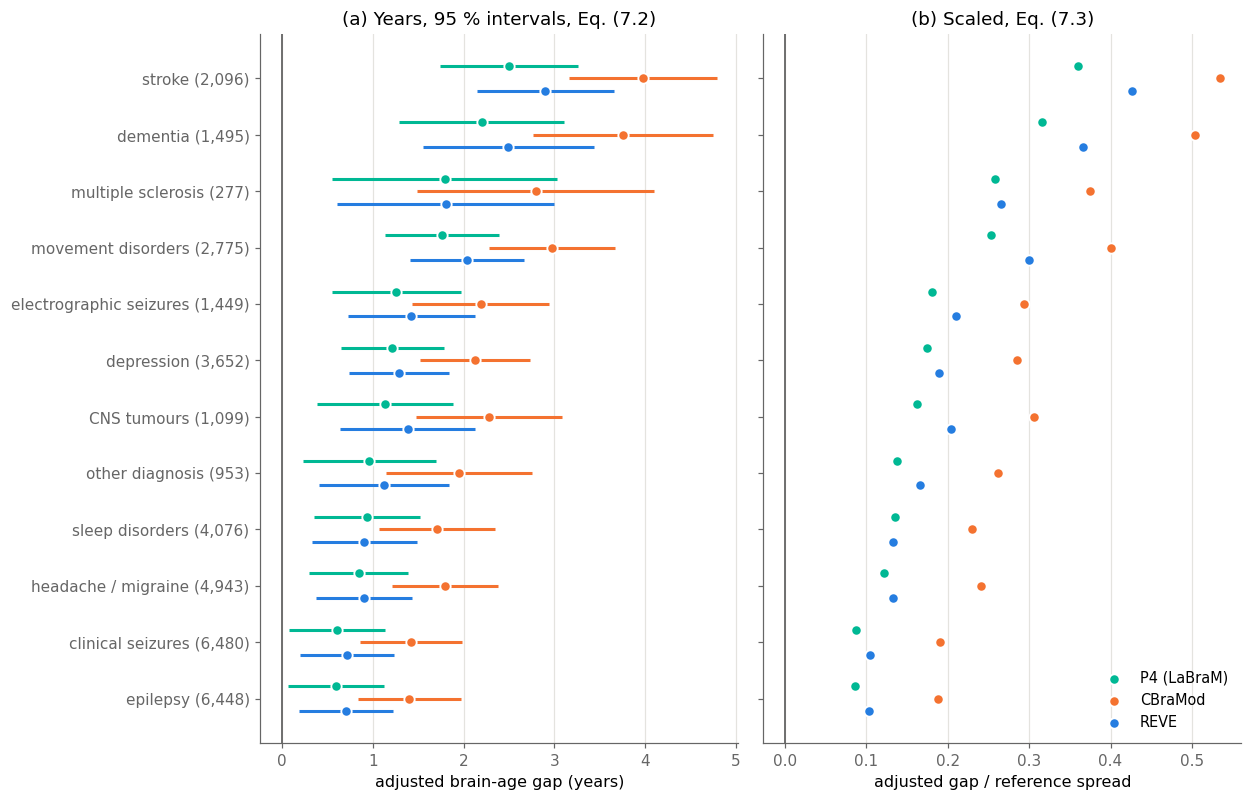

In [23]:
x = P[(P["kind"] == "pathology") & (P["family"] == "harvard")].sort_values("gapadj_P4")
yy = np.arange(len(x))
off = {"P4": 0.22, "CBraMod": 0.0, "REVE": -0.22}
fig, axes = plt.subplots(1, 2, figsize=(11.5, 7.4), sharey=True)
for ax, scaled in zip(axes, (False, True)):
    ax.axvline(0, color=fc.MUTED, lw=1.2)
    for k, m in MODELS.items():
        if scaled:
            ax.scatter(x[f"gapadj_sd_{k}"], yy + off[k], s=46, color=fc.COLOR[m], edgecolor="white", lw=1.2, zorder=3, label=m)
        else:
            ax.hlines(yy + off[k], x[f"gapadj_lo_{k}"], x[f"gapadj_hi_{k}"], color=fc.COLOR[m], lw=2, zorder=2)
            ax.scatter(x[f"gapadj_{k}"], yy + off[k], s=46, color=fc.COLOR[m], edgecolor="white", lw=1.2, zorder=3, label=m)
    ax.set_yticks(yy)
    ax.set_yticklabels([f"{g} ({int(n):,})" for g, n in zip(x["Group"], x["n"])])
    ax.set_xlabel("adjusted gap / reference spread" if scaled else "adjusted brain-age gap (years)")
    ax.set_title("Scaled, Eq. (7.3)" if scaled else "Years, 95 % intervals, Eq. (7.2)")
    fc.style(ax, "x")
axes[1].legend(loc="lower right")
finish(fig, list(axes), "pathology_gap_harvard.png")

- **REVE is better than P4 (LaBraM) in half of the Harvard pathology groups and level in the
  others** (Table 7.1): its MAE is lower in 11 of the 12 groups (multiple sclerosis +0.06), with
  an interval that excludes 0 in six (clinical seizures, epilepsy, stroke, depression, headache,
  sleep disorders). CBraMod is worse than P4 (LaBraM) in 11 of 12 groups and level in dementia.
- **All three models find every Harvard pathology group older than healthy people of the same age
  and sex** (Table 7.3, all $q$ < 0.05), in nearly the same order: stroke and dementia first (2.2
  to 4.0 years), then multiple sclerosis and movement disorders, epilepsy last (0.6 to 1.4 years)
  (Figure 7.1(a)).
- **REVE's gaps are slightly larger than P4 (LaBraM)'s, CBraMod's much larger.** REVE's adjusted
  gap is −0.04 to +0.40 years above P4 (LaBraM)'s, CBraMod's 0.8 to 1.6 years above. In units of
  the reference group's spread (Table 7.4, Figure 7.1(b)) REVE separates the groups by 0.00 to
  0.07 more than P4 (LaBraM), CBraMod by 0.10 to 0.18 more. REVE therefore combines a lower error
  on the recordings with a normal report (−0.18 years; level on the smaller healthy reference
  group, Table 7.1) with at least P4 (LaBraM)'s separation of the patient groups. Why CBraMod
  separates them most is not tested: most recordings of these groups have an abnormal report,
  and CBraMod separates abnormal from normal reports most (Figure 5.2(d)).
- **Temple groups are small** (34 to 203 people) and their intervals wide (Tables 7.2 and 7.3).
  Substance use has the largest gap that passes the false-discovery threshold in all three models
  (3.7 to 5.1 years); traumatic brain injury has a similar point estimate with a wide interval. In Temple, clinical
  seizures, epilepsy and stroke show no gap in any model, unlike in Harvard; the two data sets
  define the groups differently (TUH clinical sheet against ICD-10 codes).

### Figure 7.2. Distribution of the brain-age gap per clinical group, Harvard

The gap after the linear age-bias correction (Eq. (4.1)) for the held-out Harvard recordings of
each group and the three models; boxes as in Figure 3.2 (quartiles, median, 5th to 95th
percentile, mean); recordings and mean real age in brackets. Groups as in Section 7 (a person can
be in several pathology groups). Single recordings are not drawn.

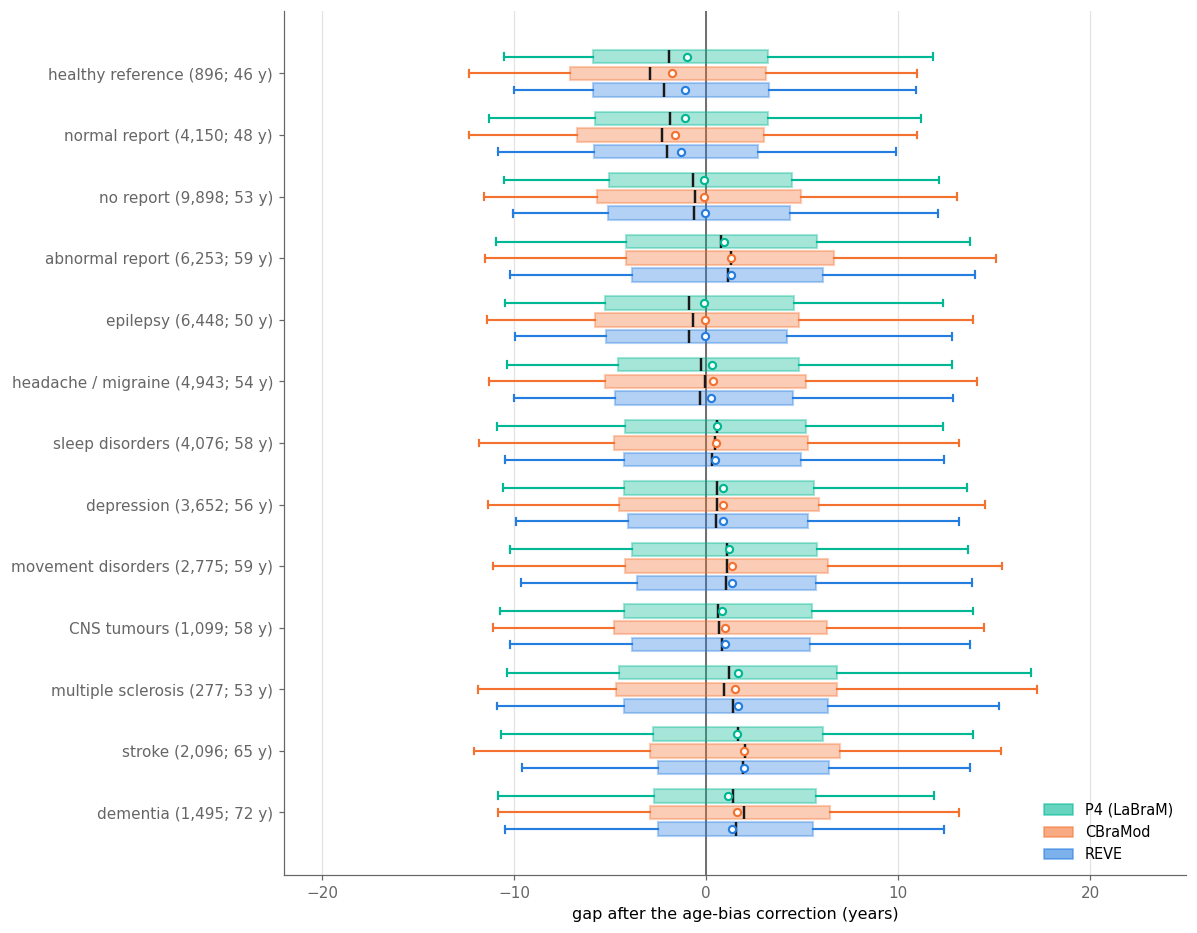

In [24]:
H = heldout[heldout["family"] == "harvard"]
Hc = {m: fc.bias_corrected(H, val, [m])[m] - H["age"] for m in fc.SINGLE}
NAMES72 = {"epilepsy": "epilepsy", "headache_disorders": "headache / migraine", "sleep_disorders": "sleep disorders",
           "depression": "depression", "movement_and_cerebellar_disorders": "movement disorders",
           "intracranial_and_spinal_tumors": "CNS tumours", "ms": "multiple sclerosis", "stroke": "stroke",
           "dementia": "dementia"}
G72 = [("healthy reference", H["reference"]), ("normal report", H["label"] == "normal"),
       ("no report", H["label"] == "unlabelled"), ("abnormal report", H["label"] == "abnormal")]
G72 += [(name, H[g] == 1) for g, name in NAMES72.items()]
fig, ax = plt.subplots(figsize=(11, 8.6))
base = np.arange(len(G72))[::-1].astype(float)
ax.axvline(0, color=fc.MUTED, lw=1.2, zorder=1)
handles = [fc.gap_boxes(ax, [Hc[m][mask].to_numpy() for _, mask in G72], base + 0.27 - 0.27 * k, fc.COLOR[m], label=m)
           for k, m in enumerate(fc.SINGLE)]
ax.set_yticks(base)
ax.set_yticklabels([f"{n} ({int(mask.sum()):,}; {H.loc[mask, 'age'].mean():.0f} y)" for n, mask in G72])
ax.set_xlabel("gap after the age-bias correction (years)")
ax.set_xlim(-22, 25)
ax.legend(handles=handles, loc="lower right")
fc.style(ax, "x")
finish(fig, None, "gap_per_group.png")

- **The groups are ordered the same way in all three models** (Figure 7.2): after the age-bias
  correction the healthy reference group has a median gap of about −2 years (−1.9 for P4 (LaBraM),
  −2.9 for CBraMod, −2.2 for REVE), abnormal reports +0.8 to +1.3, stroke and dementia +1.4 to +2.0,
  in line with the adjusted gaps of Table 7.3.
- **Within every group the gaps spread far more than the groups differ**: the middle half of a
  group covers about 9 to 10 years, two to three times the distance between the healthy reference
  and the most affected groups. The brain-age gap separates groups on average; it does not
  classify single patients.

## 8. In an ensemble with P4 (LaBraM)

### Table 8.1. P4ens (LaBraM) with one more model

MAE in years (Eq. (2.1)) of P4ens (LaBraM), of P4ens (LaBraM) + CBraMod and of P4ens (LaBraM) +
REVE; Δ against P4ens (LaBraM) (Eq. (2.2)) with its 95 % interval. The first row is the number of
parameters of all models of the ensemble. The fold-3 member is scored on the test split at its
epoch 15 (Table 4.3).

In [25]:
sets = [("Test, all", test_all), ("Test, Harvard", test_all[test_all["family"] == "harvard"]),
        ("Test, Temple", test_all[test_all["family"] == "temple"])]
sets += [(fc.NAME[c], ext[ext["cohort"] == c]) for c in fc.EXTERNAL]
T81 = fc.shown(fc.compare(sets, [fc.P4ENS, fc.P4ENS_CB, fc.P4ENS_RV], deltas=(fc.P4ENS_CB, fc.P4ENS_RV),
                          ref=fc.P4ENS), (fc.P4ENS_CB, fc.P4ENS_RV))
weights = pd.DataFrame([{"n": "–", "People": "–", fc.P4ENS: "29.2 M", fc.P4ENS_CB: "41.7 M",
                         f"Δ {fc.P4ENS_CB}": "+12.5 M", fc.P4ENS_RV: "98.5 M", f"Δ {fc.P4ENS_RV}": "+69.3 M"}],
                       index=["Parameters"])
T81 = pd.concat([weights, T81])[T81.columns]
T81.index.name = ""
table(T81, "8.1")

,n,People,P4ens (LaBraM),P4ens (LaBraM) + CBraMod,P4ens (LaBraM) + REVE,Δ P4ens (LaBraM) + CBraMod,Δ P4ens (LaBraM) + REVE
,,,,,,,
Parameters,–,–,29.2 M,41.7 M,98.5 M,+12.5 M,+69.3 M
"Test, all","7,612","6,135",5.94,5.94,5.83,"−0.00 [−0.02, +0.02]","−0.12 [−0.13, −0.10]"
"Test, Harvard","7,338","5,884",5.94,5.94,5.82,"−0.00 [−0.02, +0.02]","−0.12 [−0.14, −0.11]"
"Test, Temple",274,251,6.02,6.00,5.95,"−0.02 [−0.12, +0.08]","−0.07 [−0.16, +0.03]"
LEMON,214,214,4.67,4.69,4.59,"+0.02 [−0.06, +0.11]","−0.08 [−0.16, +0.01]"
Dortmund,"3,262",608,5.16,5.08,5.01,"−0.08 [−0.12, −0.04]","−0.15 [−0.19, −0.12]"
TDBRAIN,"2,222","1,062",5.36,5.28,5.19,"−0.08 [−0.12, −0.04]","−0.17 [−0.20, −0.13]"
SRM,152,110,4.84,4.67,4.60,"−0.17 [−0.36, +0.02]","−0.25 [−0.46, −0.04]"
CHBP,250,250,7.95,7.81,7.55,"−0.14 [−0.35, +0.06]","−0.40 [−0.57, −0.25]"


- **REVE lowers the error of P4ens (LaBraM) on every cohort** (Table 8.1), most on CHBP; the
  interval excludes 0 everywhere but on the Temple test recordings and LEMON. It helps on SRM too, where it is worse than P4 (LaBraM) alone (Table 3.1): its errors differ from P4
  (LaBraM)'s, so they partly cancel in the mean.
- **CBraMod helps on Dortmund and TDBRAIN only.**
- **On CHBP P4ens (LaBraM) is worse than P4 (LaBraM) alone** (7.95 against 7.45 years, Table 3.1):
  the other four P4 models are worse there (7.84 to 9.42 years).

## 9. Conclusions and next steps

- **REVE-base, fine-tuned with its authors' protocol, is the first encoder that is better than
  P4 (LaBraM) on this task on the same fold**: better on the test split and in every report group
  of the training hospitals, better or level in every Harvard pathology group with the pathology
  gaps kept, and level outside the training data except on SRM and at the age extremes
  (Tables 3.1, 4.2, 6.1, 7.1, 7.3).
- **Part of REVE's lead is age calibration**: after the linear age-bias correction it is level
  with P4 (LaBraM) on the test split and better on the external cohorts together, mainly on
  TDBRAIN (Table 4.4). Which model
  is better therefore depends on whether the gap is corrected for age, as brain-age studies do.
- **CBraMod is not a replacement**: worse than P4 (LaBraM) with either recipe; its predictions are
  shifted about 2 years older below 60.
- **As one more ensemble member REVE helps on every cohort** (Table 8.1), at a cost: 12 times
  P4 (LaBraM)'s weights, about 3 times the training time per fold and 3.3 times the inference time.
- **Open: the other folds.** One fold can show a gain that does not repeat. REVE's folds 1 to 4 run
  since 28 Nov, 11:20 UTC (folds 2 and 3 on SageMaker, folds 1 and 4 on the local GPU); folds 1 to
  3 end about 30 Nov, 03:00 UTC, fold 4 about 1 Dec, 19:00 UTC (`docs/fm_encoder_onboarding.md`,
  Table 7.2). With all five folds this report will compare REVE's 5-fold ensemble with P4ens
  (LaBraM) and with both together, and every training-cohort recording can be scored once out of
  fold for the pathology analysis.
- **Not yet explained:** REVE's loss on SRM and at the age extremes outside the training data,
  and which settings of the authors' protocol carry the gain over the P4 recipe.